In [1]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
import fifpy
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label, gaussian_filter
from scipy.stats import lognorm, gaussian_kde

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.detection import detect_current_sheets
from shared.fields import partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.thickness import caliper_length, crop_with_border, thickness_m1
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("cs_identification")
CACHE = shared_cache_dir("cs_identification")

In [2]:
#Defining all the required functions

#Fourier Transform Functions


#Defining constants
dx = 0.0625
dy = 0.0625






--- beta = 0.25, t = 200 ---
Loading cached filtered fields ...
found 258 sheets


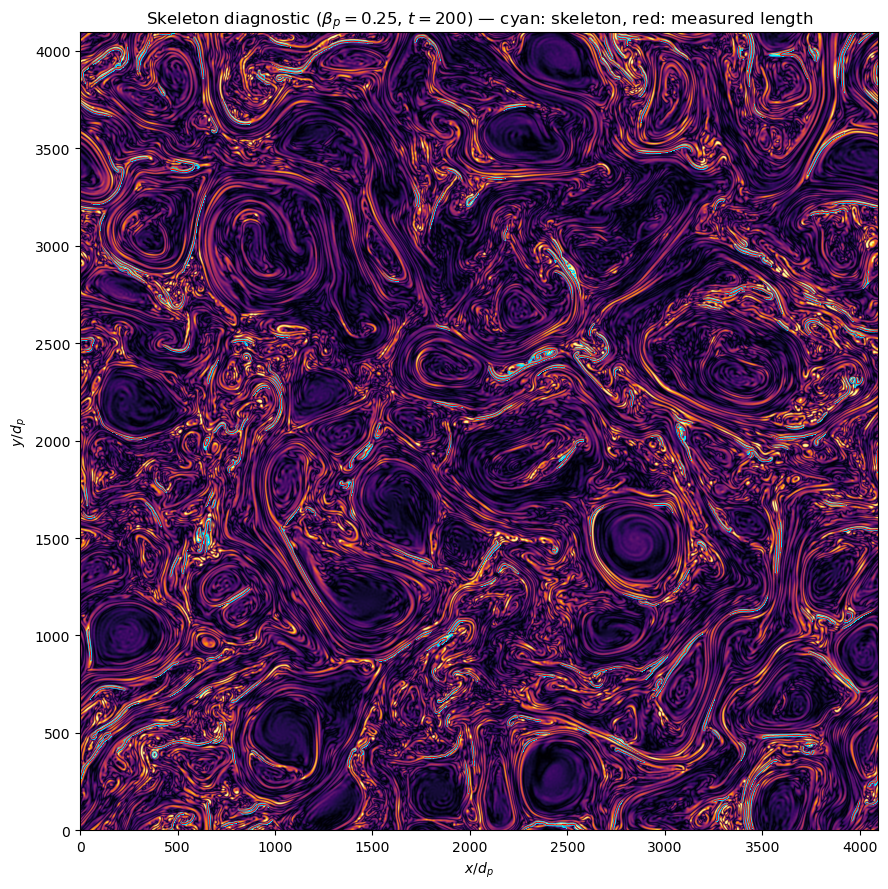

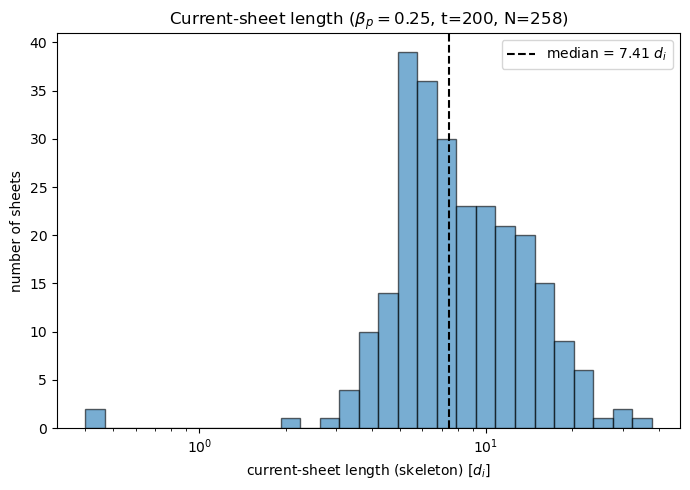


--- length summary (pooled) ---
sheets measured        : 258
length  (skeleton)     : median = 7.41, mean = 9.19 d_i
length  (caliper)      : median = 7.03 d_i
tortuosity (skel/cal)  : median = 1.05
thickness (M1)         : median = 0.729 d_i
aspect ratio (L/thick) : median = 10.8
sheets with aspect > 50: 0  (tearing/plasmoid-unstable candidates)

Saved in:  cs_length_beta0.25/


In [4]:
# ============================================================
#  Current-sheet LENGTH from your detection masks
#  ------------------------------------------------------------
#  Runs your current-sheet detection (filter -> |Jz| -> detect_current_sheets
#  -> morphology), then for every sheet measures:
#     - length      : longest path along the skeleton (branches ignored)
#     - caliper      : Zhdankin-style max-caliper (straight-line) length
#     - tortuosity  : length / caliper   (~1 straight, >1 curved)
#     - thickness   : inscribed-circle (M1), for the aspect ratio
#     - aspect ratio: length / thickness
#  and writes:
#     - a skeleton DIAGNOSTIC overview per snapshot (skeletons + longest paths
#       overlaid on |Jz|), plus optional per-sheet cards
#     - a pooled length PDF, a per-sheet CSV, and a printed summary
#
#  Needs from your session: iterative_filtering3D, partial_x_fft,
#                           partial_y_fft, detect_current_sheets
# ============================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
import h5py
from skimage import morphology, measure
from skimage.morphology import skeletonize
from scipy import ndimage as ndi
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

# -----------------------------
# USER SETTINGS
# -----------------------------
beta      = 0.25                       # 0.0625, 0.25, 1, 4, 16
times     = [200]                      # add snapshots to pool, e.g. [200, 205, 210]
sim_tag   = "ApJ"
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"

cache_dir = str(CACHE / "filtered_cache_Jz")
out_dir   = str(RESULTS / f"cs_length_beta{beta}")

px_per_di = 16.0                       # pixels per ion inertial length
CONNECTIVITY = 2                       # 8-connectivity, consistent with your thickness work

SAVE_SHEET_VISUALS = True              # per-sheet skeleton cards (set False for just stats)
MAX_SHEETS_VIS     = 30                # cap on per-sheet cards per snapshot
MIN_LENGTH_DI      = 0.0               # drop sheets shorter than this from stats (resolution floor)

dx = dy = 0.0625

os.makedirs(cache_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)


def filter_params(b):
    if b == 0.0625: return 3, 2.0
    if b == 0.25:   return 3, 2.3
    if b == 1:      return 3, 2.5
    if b == 4:      return 3, 2.7
    return 3, 3.0


# ============================================================
# Geometry helpers
# ============================================================
def skeleton_length(region, step=1.0, fill_holes=True, return_path=False):
    """
    Length of a sheet region = longest path along its skeleton (the skeleton
    graph diameter). Branches are ignored. Diagonal steps weighted by sqrt(2).
    `step` is the physical size of one pixel (pass 1/px_per_di for d_i).
    Skeletonization is done on the region's bounding box for speed; returned
    pixel coordinates are in the full-frame (global) index space.
    """
    region = np.asarray(region, bool)
    xs, ys = np.where(region)
    if len(xs) == 0:
        return (0.0, np.empty((0, 2), int), np.empty((0, 2), int)) if return_path else 0.0
    x0, x1 = xs.min(), xs.max() + 1
    y0, y1 = ys.min(), ys.max() + 1
    off = np.array([x0, y0])

    reg = region[x0:x1, y0:y1]
    if fill_holes:
        reg = ndi.binary_fill_holes(reg)          # enclosed island -> no skeleton loop
    skel = skeletonize(reg)
    coords = np.argwhere(skel)                     # crop-frame ij
    n = len(coords)
    if n < 2:
        g = coords + off
        return (0.0, g, g) if return_path else 0.0

    idx = {(int(i), int(j)): k for k, (i, j) in enumerate(coords)}
    rows, cols, wts = [], [], []
    for k, (i, j) in enumerate(coords):
        for di in (-1, 0, 1):
            for dj in (-1, 0, 1):
                if di == 0 and dj == 0:
                    continue
                m = idx.get((int(i) + di, int(j) + dj))
                if m is not None and m > k:
                    w = np.hypot(di, dj) * step
                    rows += [k, m]; cols += [m, k]; wts += [w, w]
    graph = csr_matrix((wts, (rows, cols)), shape=(n, n))

    d0 = dijkstra(graph, indices=0, directed=False); d0[np.isinf(d0)] = -1
    a = int(np.argmax(d0))
    dist, pred = dijkstra(graph, indices=a, directed=False, return_predecessors=True)
    dist[np.isinf(dist)] = -1
    b = int(np.argmax(dist))
    length = float(dist[b])
    if not return_path:
        return length

    node, pn = b, []
    while node != -9999 and node >= 0:
        pn.append(node); node = int(pred[node])
    skel_ij = coords + off
    path_ij = coords[pn[::-1]] + off
    return length, skel_ij, path_ij


# ============================================================
# MAIN LOOP (over times) -- detection is exactly your pipeline
# ============================================================
step_di = 1.0 / px_per_di              # one pixel in units of d_i

J2_all, labeled_all = {}, {}
skel_pts_all, paths_all = {}, {}       # for the diagnostic overview
rows_csv = []                          # per-sheet measurements (pooled)

for time in times:
    print(f"\n--- beta = {beta}, t = {time} ---", flush=True)

    with h5py.File(base_path + f"Bx_{sim_tag}_t{time}.h5", "r") as fBx, \
         h5py.File(base_path + f"By_{sim_tag}_t{time}.h5", "r") as fBy, \
         h5py.File(base_path + f"Bz_{sim_tag}_t{time}.h5", "r") as fBz:
        data_Bx = fBx["DS1"][:].T
        data_By = fBy["DS1"][:].T
        data_Bz = fBz["DS1"][:].T

    n_iter, Xi = filter_params(beta)
    cache_file = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cache_file):
        print("Loading cached filtered fields ...", flush=True)
        d = np.load(cache_file)
        data_Bx_f, data_By_f, data_Bz_f = d["Bx"], d["By"], d["Bz"]
    else:
        print("Computing filtering (slow) ...", flush=True)
        data_Bx_f, data_By_f, data_Bz_f = iterative_filtering3D(
            data_Bx, data_By, data_Bz, n_iter, Xi=Xi)
        np.savez_compressed(cache_file, Bx=data_Bx_f, By=data_By_f, Bz=data_Bz_f)

    # current density and mask (your steps)
    Jz = partial_x_fft(data_By_f, dy) - partial_y_fft(data_Bx_f, dx)
    J2 = np.abs(Jz)

    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    mask = morphology.remove_small_objects(mask.astype(bool), min_size=500).astype(int)

    labeled = measure.label(mask, connectivity=CONNECTIVITY)
    n_sheets = labeled.max()
    print(f"found {n_sheets} sheets", flush=True)

    # per-sheet measurements
    skel_pts, paths = [], []
    for k in range(1, n_sheets + 1):
        region = (labeled == k)
        L, skel_ij, path_ij = skeleton_length(region, step=step_di, return_path=True)
        if L < MIN_LENGTH_DI:
            continue
        cal = caliper_length(region, step=step_di)
        th  = thickness_m1(region, step=step_di)
        tort   = L / cal if cal > 0 else np.nan
        aspect = L / th  if th  > 0 else np.nan
        rows_csv.append([time, k, L, cal, tort, th, aspect])
        skel_pts.append(skel_ij)
        paths.append(path_ij)

    J2_all[time]      = J2
    labeled_all[time] = labeled
    skel_pts_all[time] = skel_pts
    paths_all[time]    = paths


# ============================================================
# DIAGNOSTIC OVERVIEW: skeletons + longest paths on |Jz|
# ============================================================
for time in times:
    J2 = J2_all[time]
    vmax = np.percentile(J2.ravel(), 99)

    fig, ax = plt.subplots(figsize=(9, 9))
    ax.imshow(J2.T, cmap="inferno", origin="lower", vmax=vmax)
    ax.contour((labeled_all[time] > 0).T, levels=[0.5], colors="deepskyblue", linewidths=0.5)
    for skel_ij in skel_pts_all[time]:             # full skeletons (thin)
        if len(skel_ij):
            ax.scatter(skel_ij[:, 0], skel_ij[:, 1], s=0.5, c="cyan", linewidths=0)
    for path_ij in paths_all[time]:                # measured longest paths
        if len(path_ij) > 1:
            ax.plot(path_ij[:, 0], path_ij[:, 1], "-", c="red", lw=0.7)
    ax.set_title(fr"Skeleton diagnostic ($\beta_p={beta}$, $t={time}$) "
                 fr"— cyan: skeleton, red: measured length")
    ax.set_xlabel(r"$x/d_p$"); ax.set_ylabel(r"$y/d_p$")
    plt.tight_layout()
    plt.savefig(f"{out_dir}/skeleton_overview_t{time}.png", dpi=250)
    plt.show()


# ============================================================
# Optional per-sheet cards
# ============================================================
if SAVE_SHEET_VISUALS:
    for time in times:
        card_dir = f"{out_dir}/sheets_t{time}"
        os.makedirs(card_dir, exist_ok=True)
        J2 = J2_all[time]; labeled = labeled_all[time]
        vmax = np.percentile(J2.ravel(), 99)
        rows_t = [r for r in rows_csv if r[0] == time]
        for r in rows_t[:MAX_SHEETS_VIS]:
            k, L, cal, tort, th = r[1], r[2], r[3], r[4], r[5]
            region = (labeled == k)
            _, skel_ij, path_ij = skeleton_length(region, step=step_di, return_path=True)

            xs, ys = np.where(region); pad = 15
            x0 = max(0, xs.min() - pad); x1 = min(region.shape[0], xs.max() + pad + 1)
            y0 = max(0, ys.min() - pad); y1 = min(region.shape[1], ys.max() + pad + 1)

            fig, ax = plt.subplots(figsize=(6, 5))
            ax.imshow(J2[x0:x1, y0:y1].T, cmap="inferno", origin="lower",
                      extent=[x0, x1, y0, y1], vmax=vmax)
            ax.contour(region[x0:x1, y0:y1].T, levels=[0.5], colors="white",
                       linewidths=1.0, extent=[x0, x1, y0, y1])
            if len(skel_ij):
                ax.scatter(skel_ij[:, 0], skel_ij[:, 1], s=3, c="cyan", linewidths=0)
            if len(path_ij) > 1:
                ax.plot(path_ij[:, 0], path_ij[:, 1], "-", c="red", lw=1.5)
                ax.scatter([path_ij[0, 0], path_ij[-1, 0]], [path_ij[0, 1], path_ij[-1, 1]],
                           c="yellow", edgecolors="k", s=45, zorder=5)
            ax.set_title(f"sheet {k}:  L={L:.2f} $d_i$   caliper={cal:.2f}   tort={tort:.2f}")
            ax.set_xlabel(r"$x/d_p$"); ax.set_ylabel(r"$y/d_p$")
            plt.tight_layout()
            plt.savefig(f"{card_dir}/sheet_{k:03d}.png", dpi=130)
            plt.close()


# ============================================================
# Pooled length PDF + CSV + summary
# ============================================================
rows_csv = np.array(rows_csv, dtype=float) if rows_csv else np.empty((0, 7))
if len(rows_csv) == 0:
    raise SystemExit("No sheets measured (check paths / times / MIN_LENGTH_DI).")

L_skel   = rows_csv[:, 2]
L_cal    = rows_csv[:, 3]
tort     = rows_csv[:, 4]
thick    = rows_csv[:, 5]
aspect   = rows_csv[:, 6]

# length PDF (pooled across the chosen snapshots)
plt.figure(figsize=(7, 5))
bins = np.logspace(np.log10(L_skel.min()), np.log10(L_skel.max()), 30)
plt.hist(L_skel, bins=bins, alpha=0.6, edgecolor="black")
plt.axvline(np.median(L_skel), color="black", linestyle="--",
            label=f"median = {np.median(L_skel):.2f} $d_i$")
plt.xscale("log")
plt.xlabel(r"current-sheet length (skeleton) $[d_i]$")
plt.ylabel("number of sheets")
tt = f"t={times[0]}" if len(times) == 1 else f"pooled t={times[0]}$-${times[-1]}"
plt.title(fr"Current-sheet length ($\beta_p={beta}$, {tt}, N={len(L_skel)})")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/length_pdf_beta{beta}.png", dpi=300)
plt.show()

# per-sheet CSV
with open(f"{out_dir}/lengths_beta{beta}.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["time", "sheet_id", "length_skel_di", "length_caliper_di",
                "tortuosity", "thickness_di", "aspect_ratio"])
    for r in rows_csv:
        w.writerow([int(r[0]), int(r[1]), r[2], r[3], r[4], r[5], r[6]])

# summary
n_plasmoid = int(np.sum(aspect > 50))
print("\n--- length summary (pooled) ---")
print(f"sheets measured        : {len(L_skel)}")
print(f"length  (skeleton)     : median = {np.median(L_skel):.2f}, mean = {np.mean(L_skel):.2f} d_i")
print(f"length  (caliper)      : median = {np.median(L_cal):.2f} d_i")
print(f"tortuosity (skel/cal)  : median = {np.median(tort):.2f}")
print(f"thickness (M1)         : median = {np.median(thick):.3f} d_i")
print(f"aspect ratio (L/thick) : median = {np.median(aspect):.1f}")
print(f"sheets with aspect > 50: {n_plasmoid}  (tearing/plasmoid-unstable candidates)")
print(f"\nSaved in:  {out_dir}/")

measuring 11 snapshots on 11 workers ...
  t=225: 79 sheets
  t=250: 99 sheets
  t=245: 98 sheets
  t=240: 100 sheets
  t=235: 102 sheets
  t=230: 107 sheets
  t=205: 103 sheets
  t=210: 105 sheets
  t=220: 108 sheets
  t=215: 112 sheets
  t=200: 107 sheets

pooled 1120 sheets from 11 snapshots
saved -> cs_length_beta16/lengths_beta16.npz (+ .csv)
1120 sheets (rings were already skipped in CELL 1)


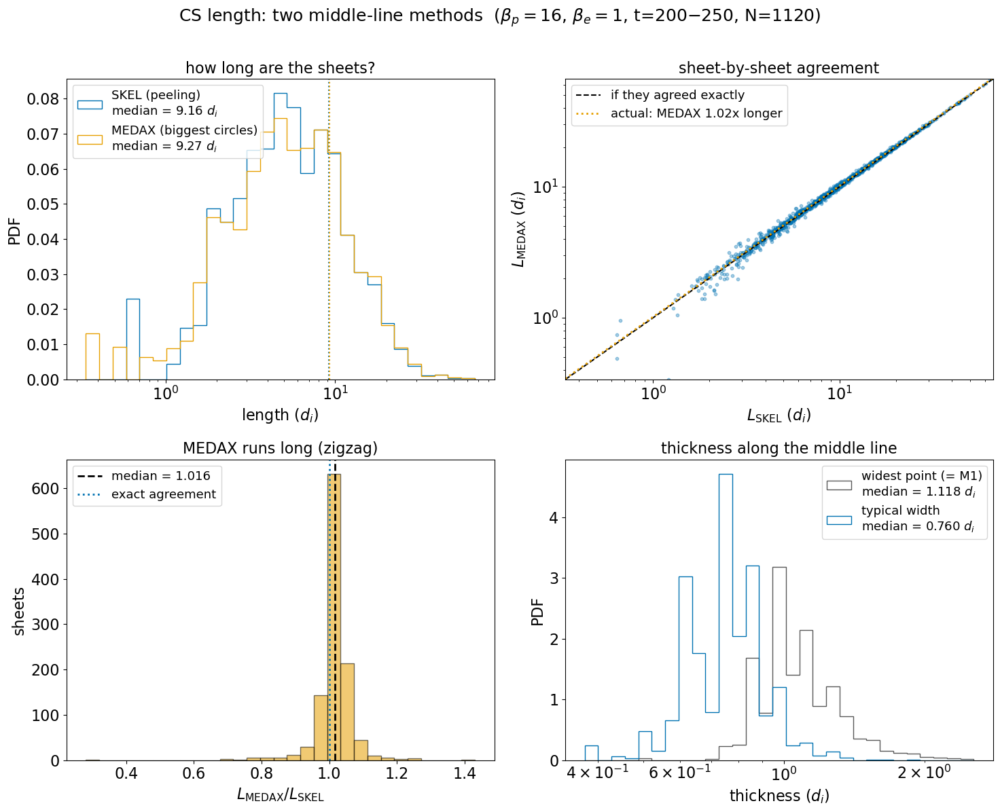


t=200: drawing 107 sheets


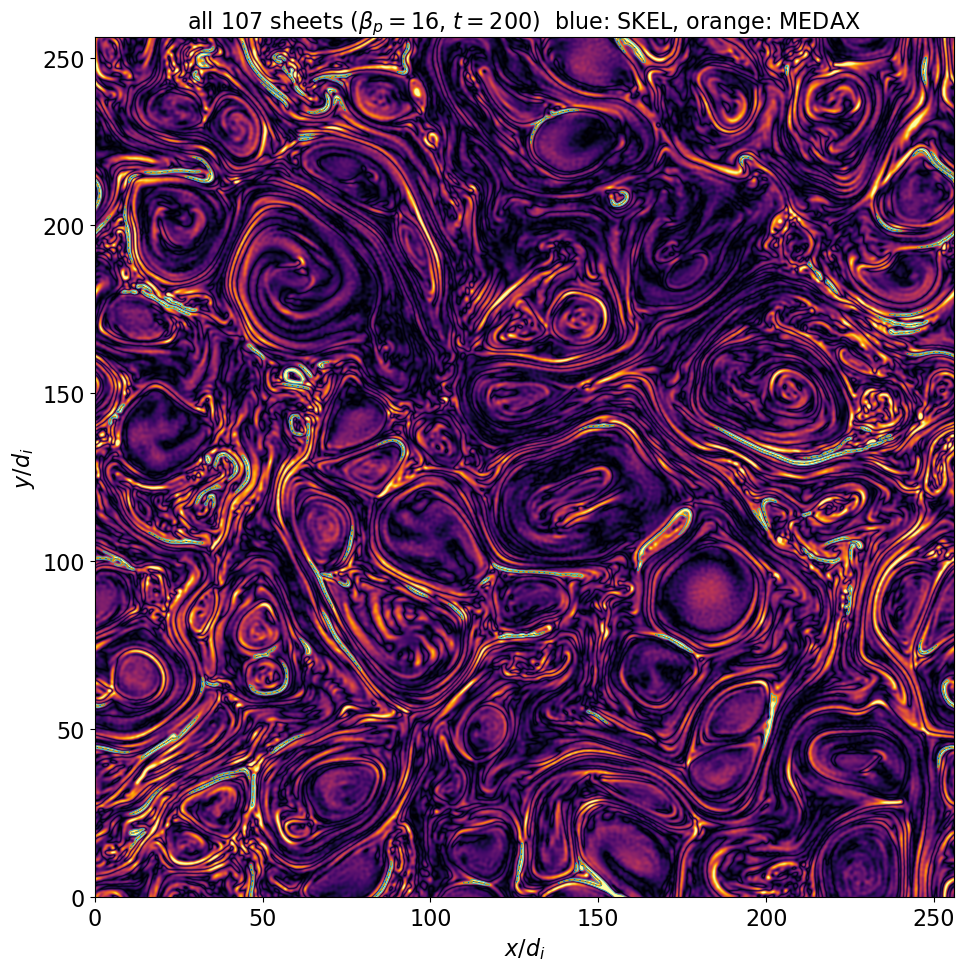

   overview: good for checking the detection; at 256 d_i across the box the two centrelines overlap, so use the montage to compare them


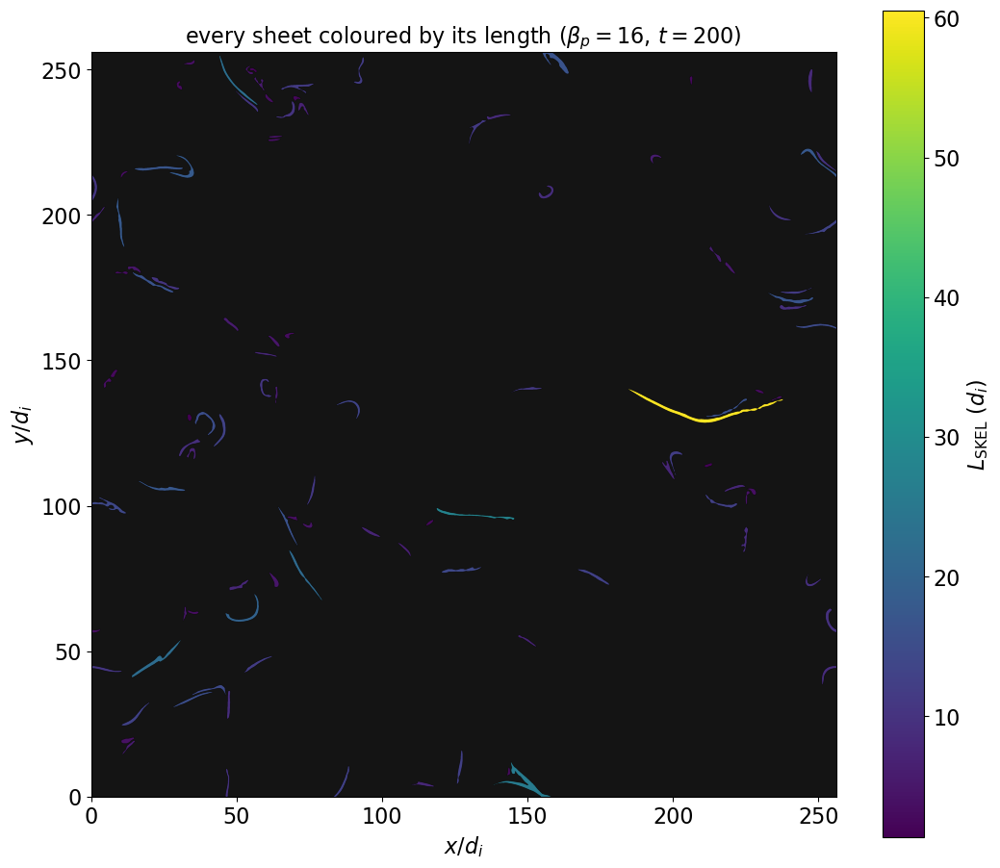

   map: blank sheets are the ones skipped as rings
   montage: 6 page(s) -> cs_length_beta16/montage_t200_page*.png
   cards: 107 -> cs_length_beta16/sheets_t200/

t=205: drawing 103 sheets


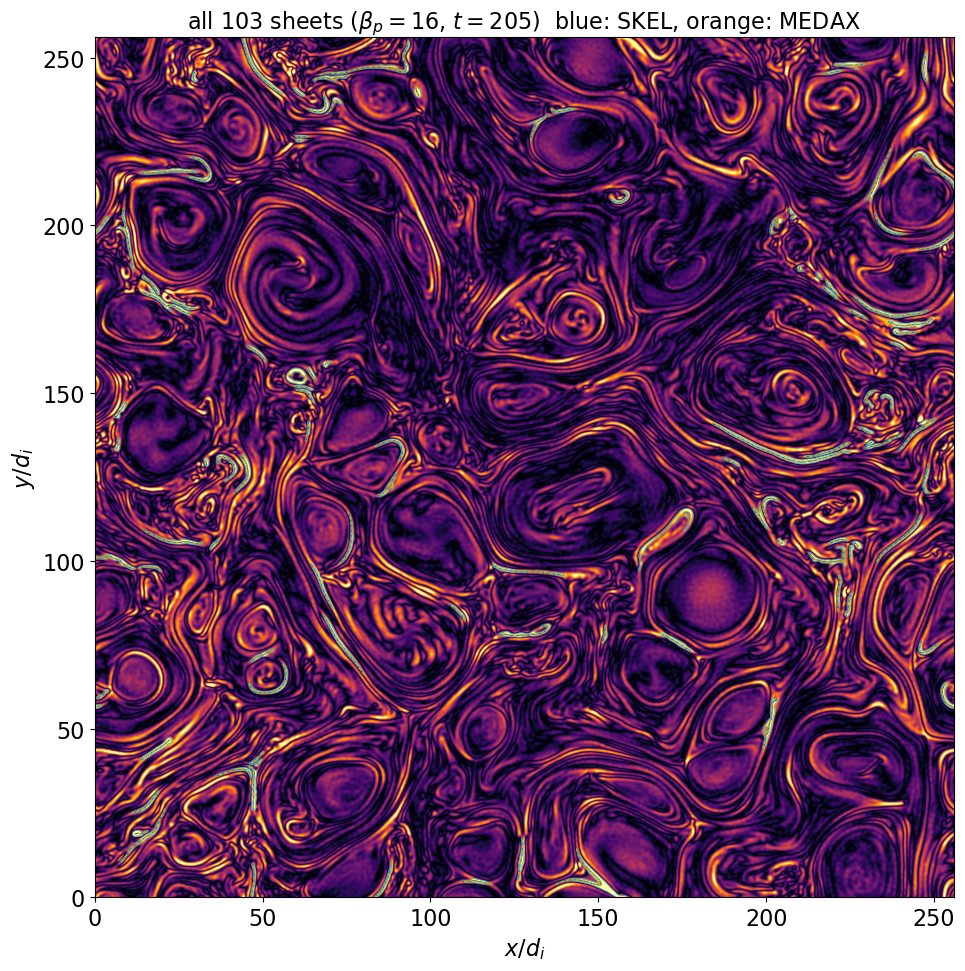

   overview: good for checking the detection; at 256 d_i across the box the two centrelines overlap, so use the montage to compare them


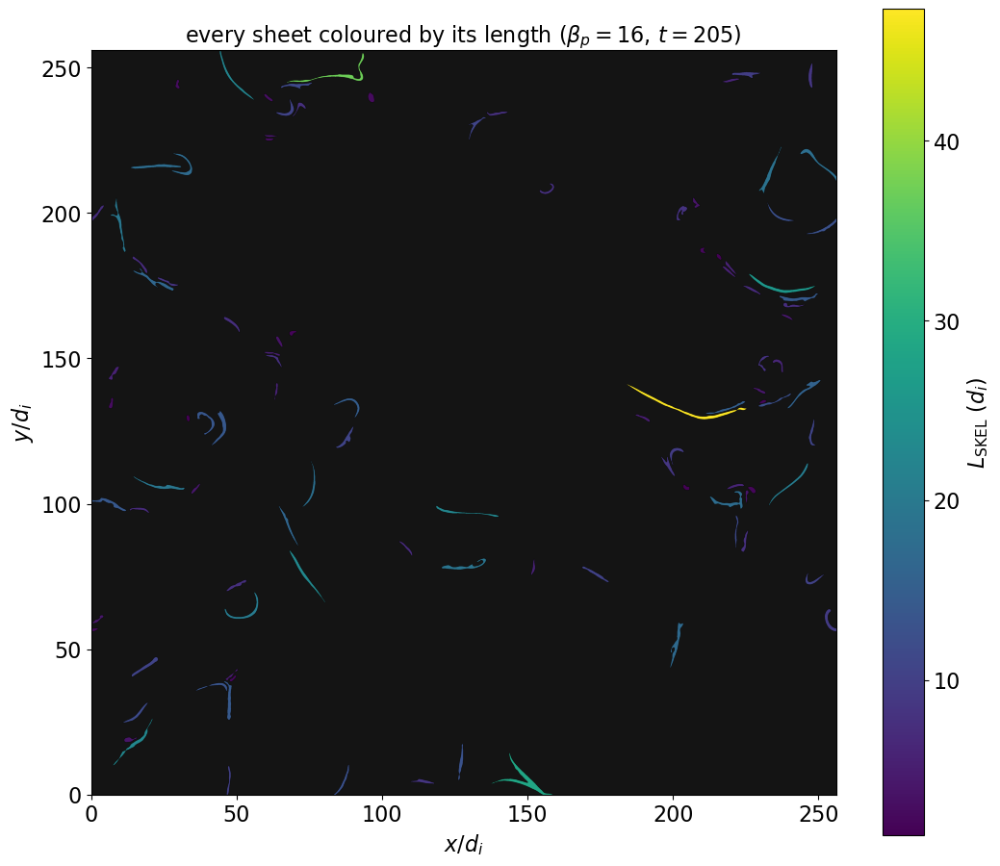

   map: blank sheets are the ones skipped as rings
   montage: 6 page(s) -> cs_length_beta16/montage_t205_page*.png
   cards: 103 -> cs_length_beta16/sheets_t205/

t=210: drawing 105 sheets


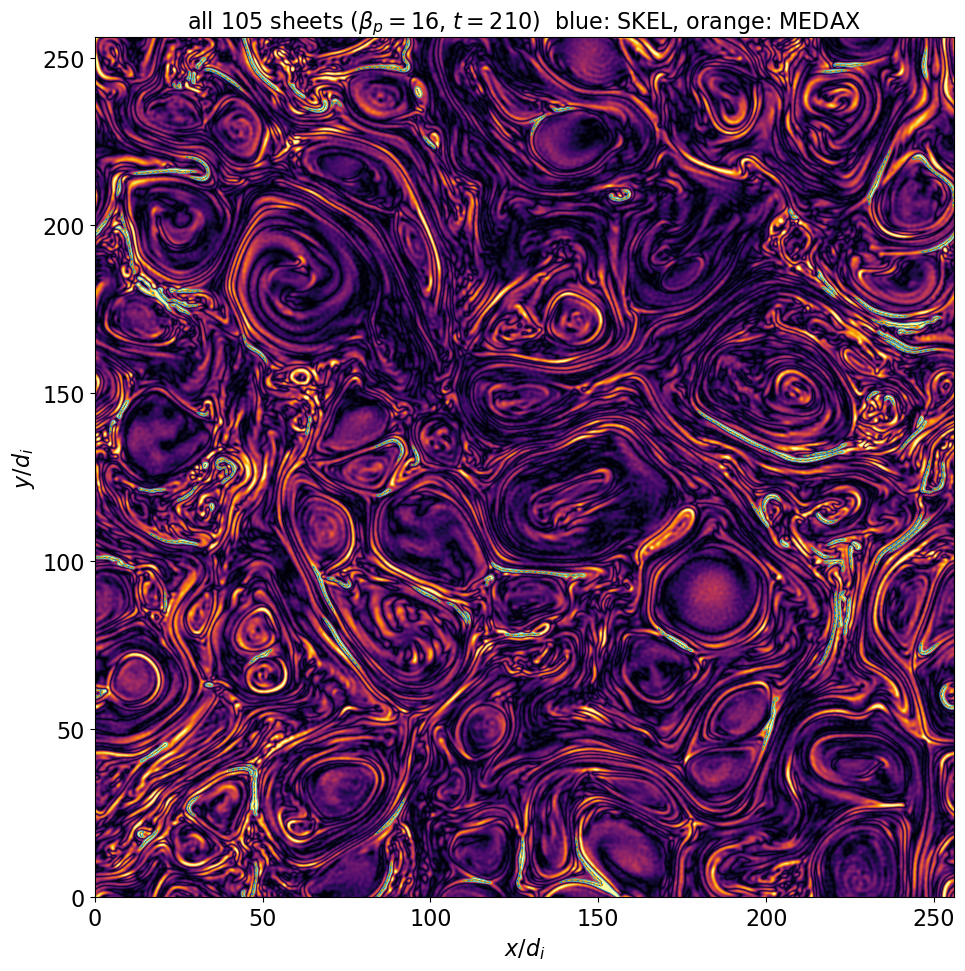

   overview: good for checking the detection; at 256 d_i across the box the two centrelines overlap, so use the montage to compare them


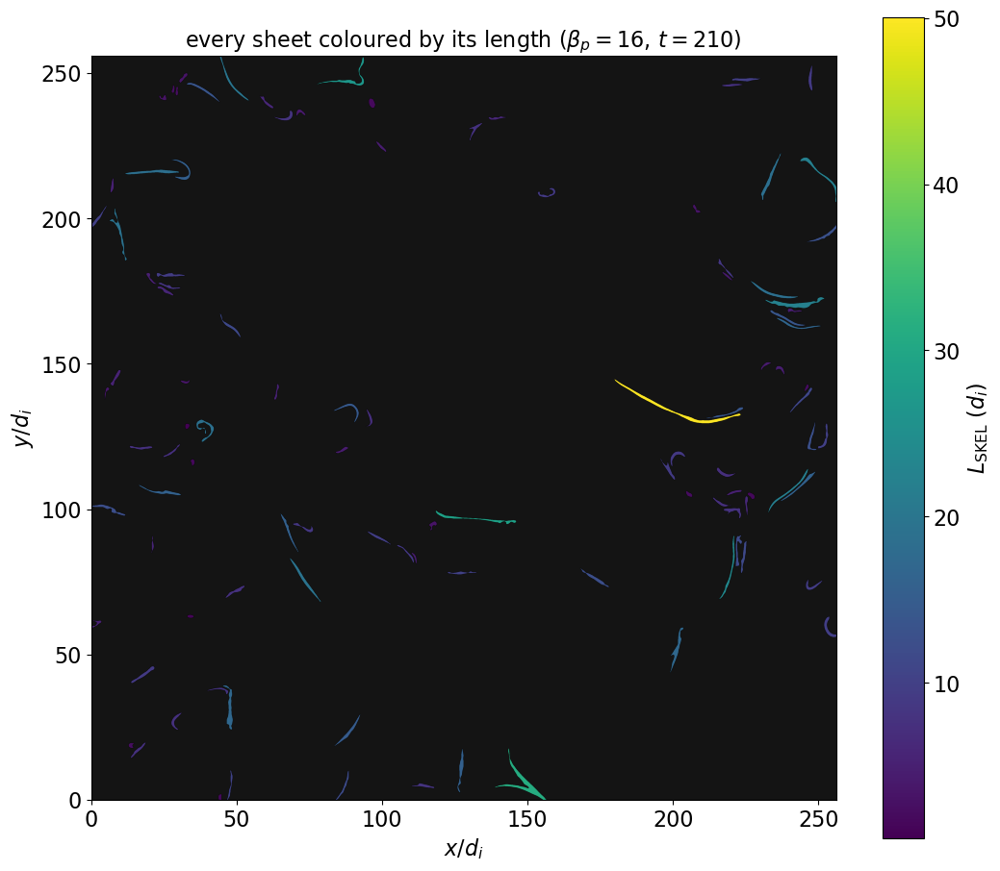

   map: blank sheets are the ones skipped as rings
   montage: 6 page(s) -> cs_length_beta16/montage_t210_page*.png
   cards: 105 -> cs_length_beta16/sheets_t210/

t=215: drawing 112 sheets


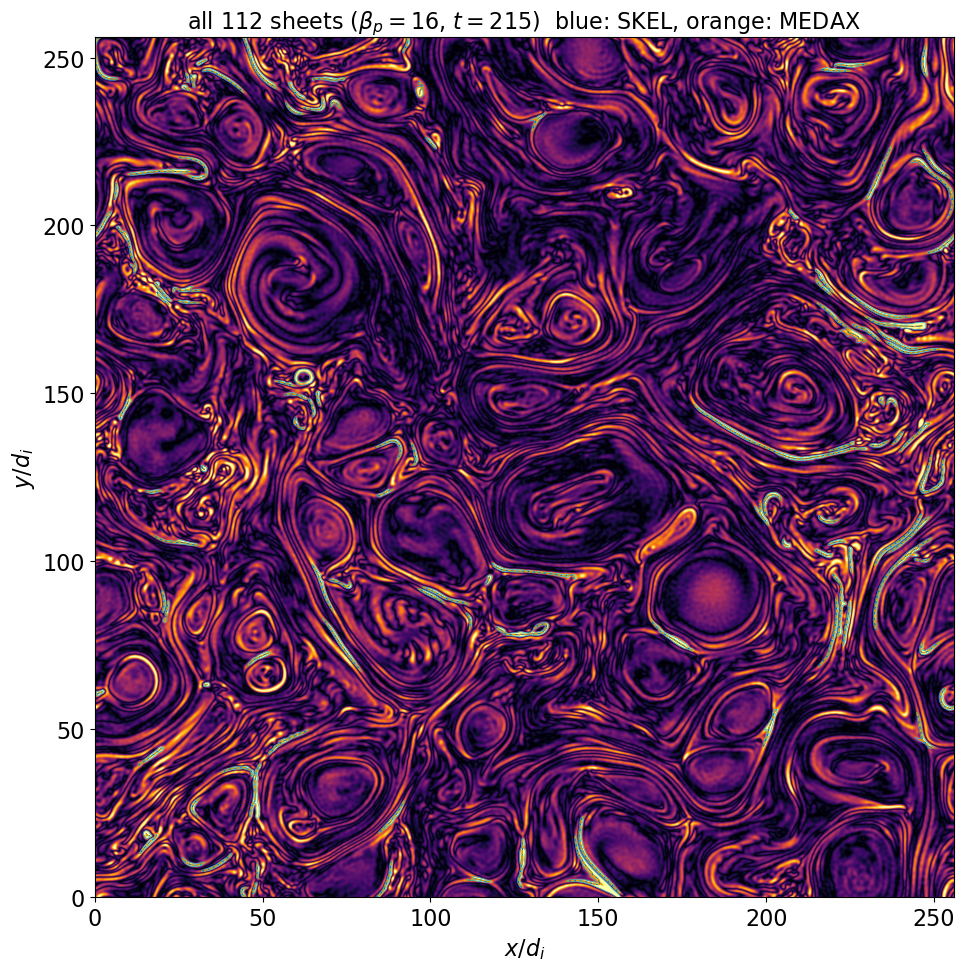

   overview: good for checking the detection; at 256 d_i across the box the two centrelines overlap, so use the montage to compare them


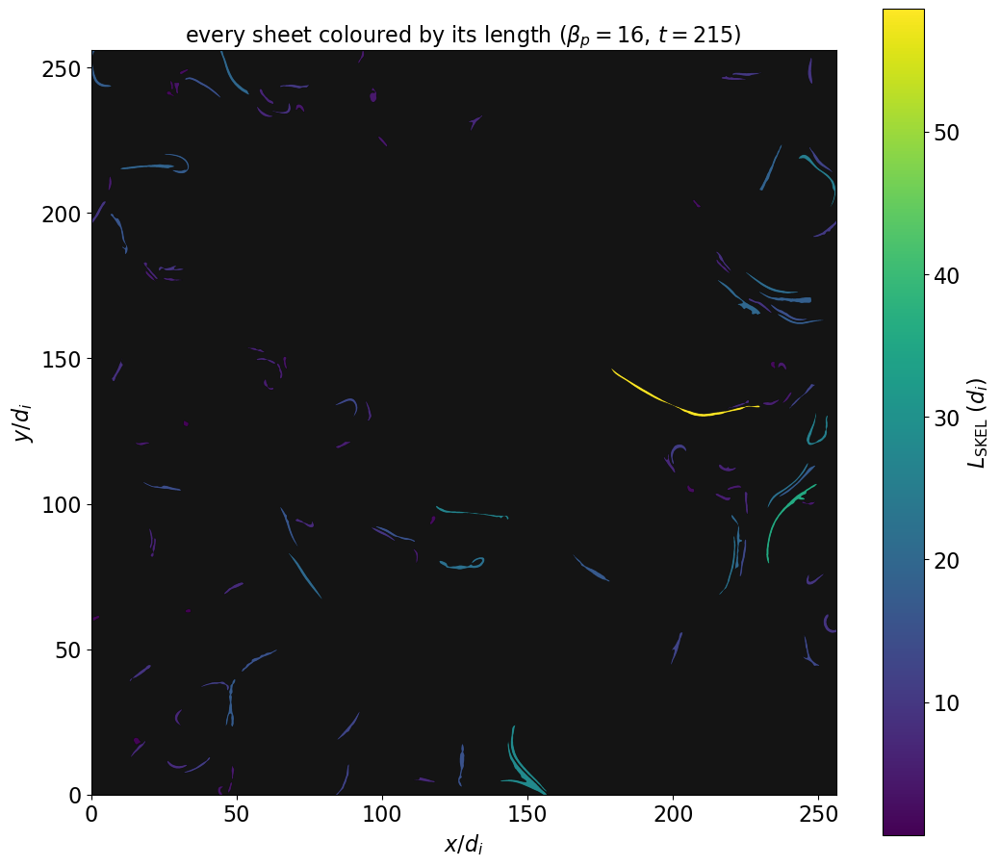

   map: blank sheets are the ones skipped as rings
   montage: 7 page(s) -> cs_length_beta16/montage_t215_page*.png
   cards: 112 -> cs_length_beta16/sheets_t215/

t=220: drawing 108 sheets


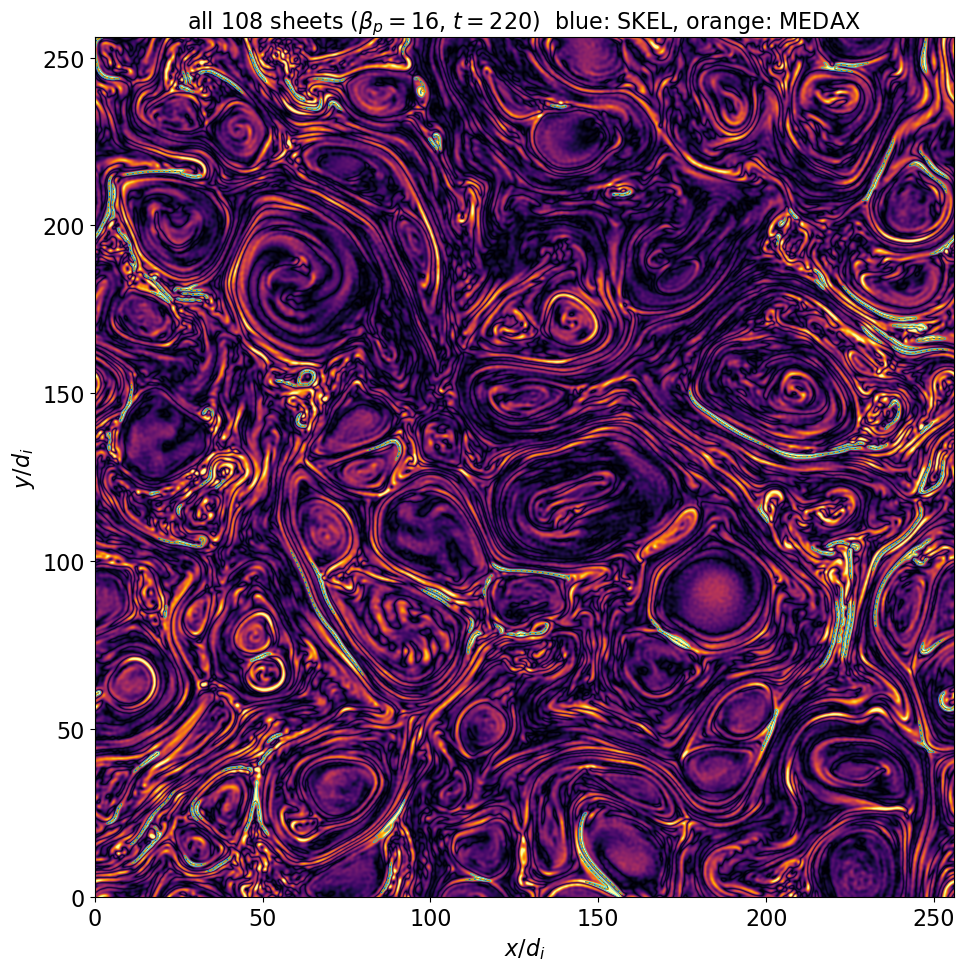

   overview: good for checking the detection; at 256 d_i across the box the two centrelines overlap, so use the montage to compare them


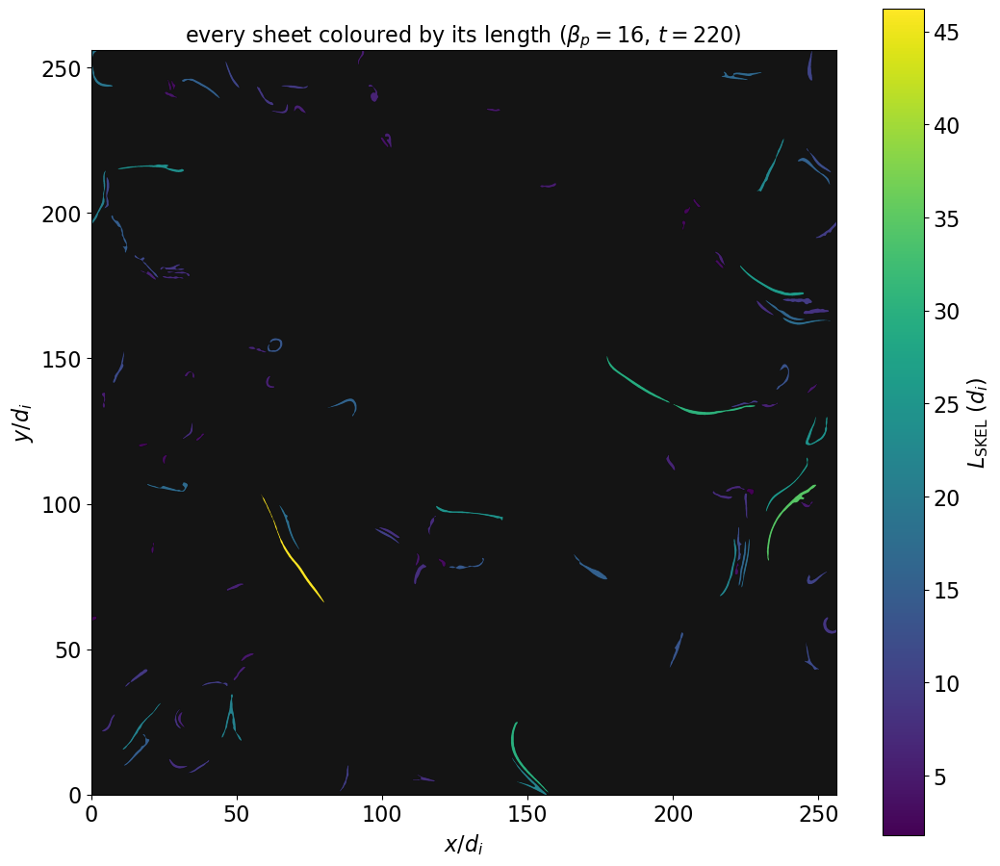

   map: blank sheets are the ones skipped as rings
   montage: 6 page(s) -> cs_length_beta16/montage_t220_page*.png
   cards: 108 -> cs_length_beta16/sheets_t220/

t=225: drawing 79 sheets


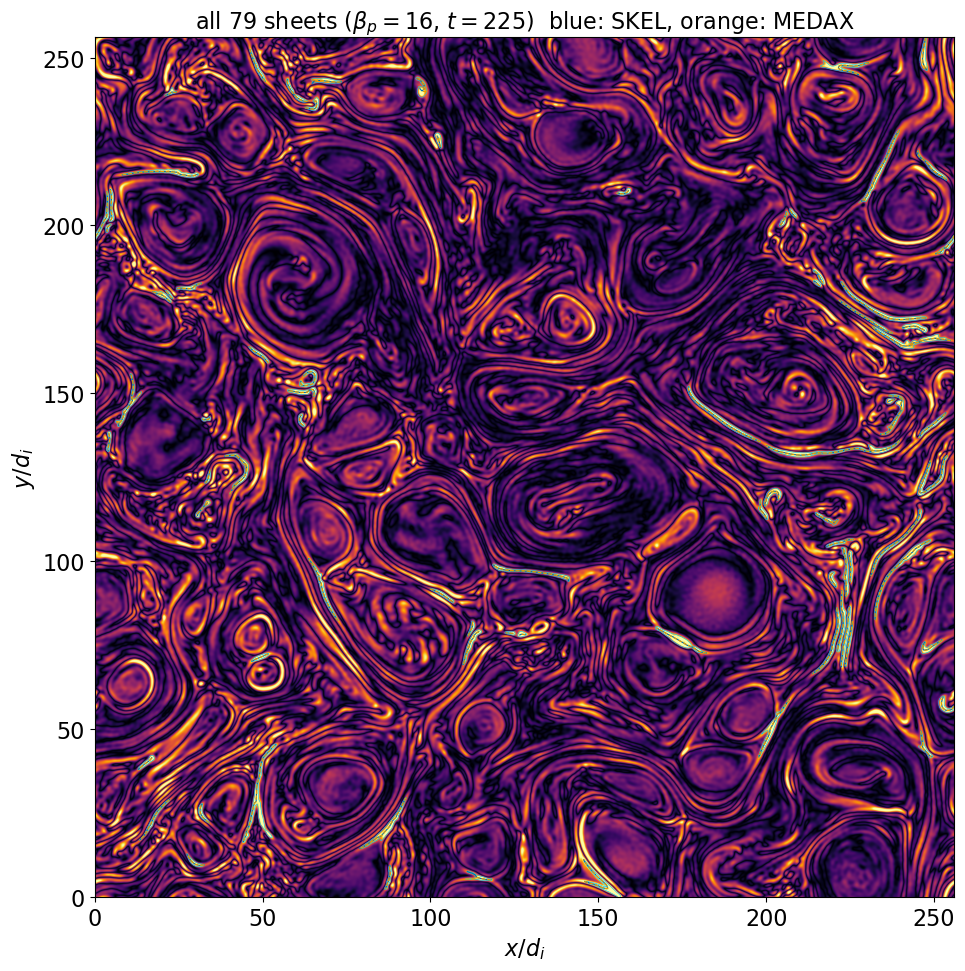

   overview: good for checking the detection; at 256 d_i across the box the two centrelines overlap, so use the montage to compare them


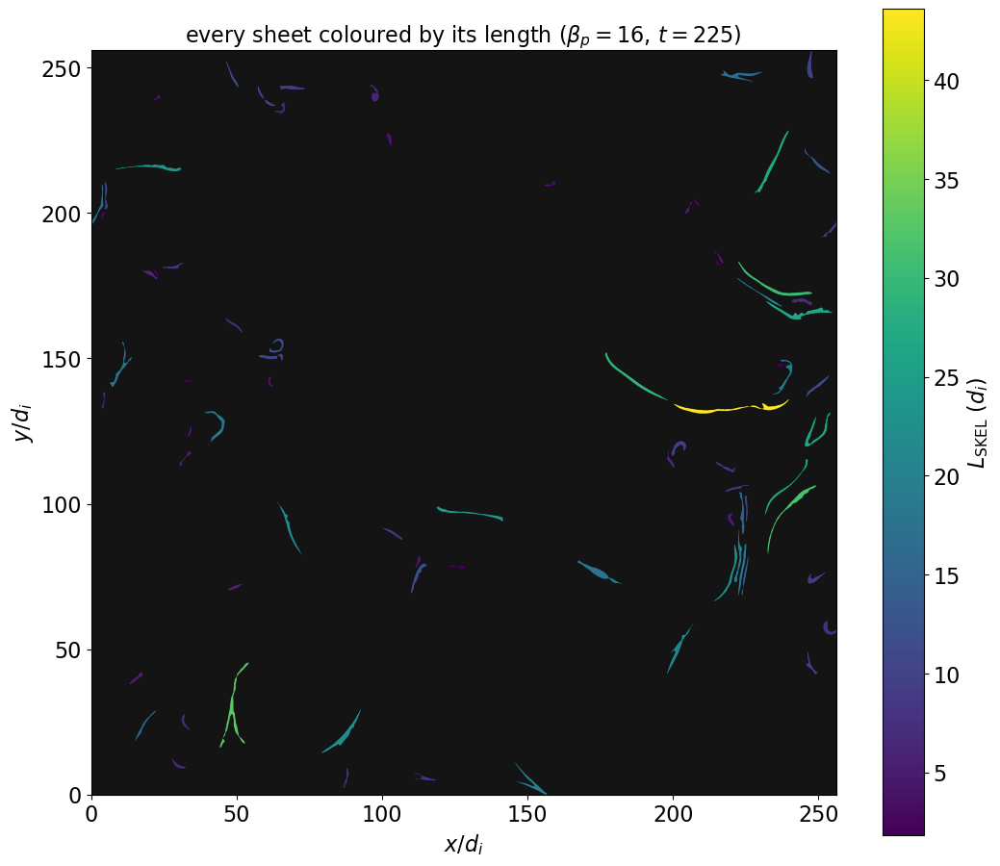

   map: blank sheets are the ones skipped as rings
   montage: 5 page(s) -> cs_length_beta16/montage_t225_page*.png
   cards: 79 -> cs_length_beta16/sheets_t225/

t=230: drawing 107 sheets


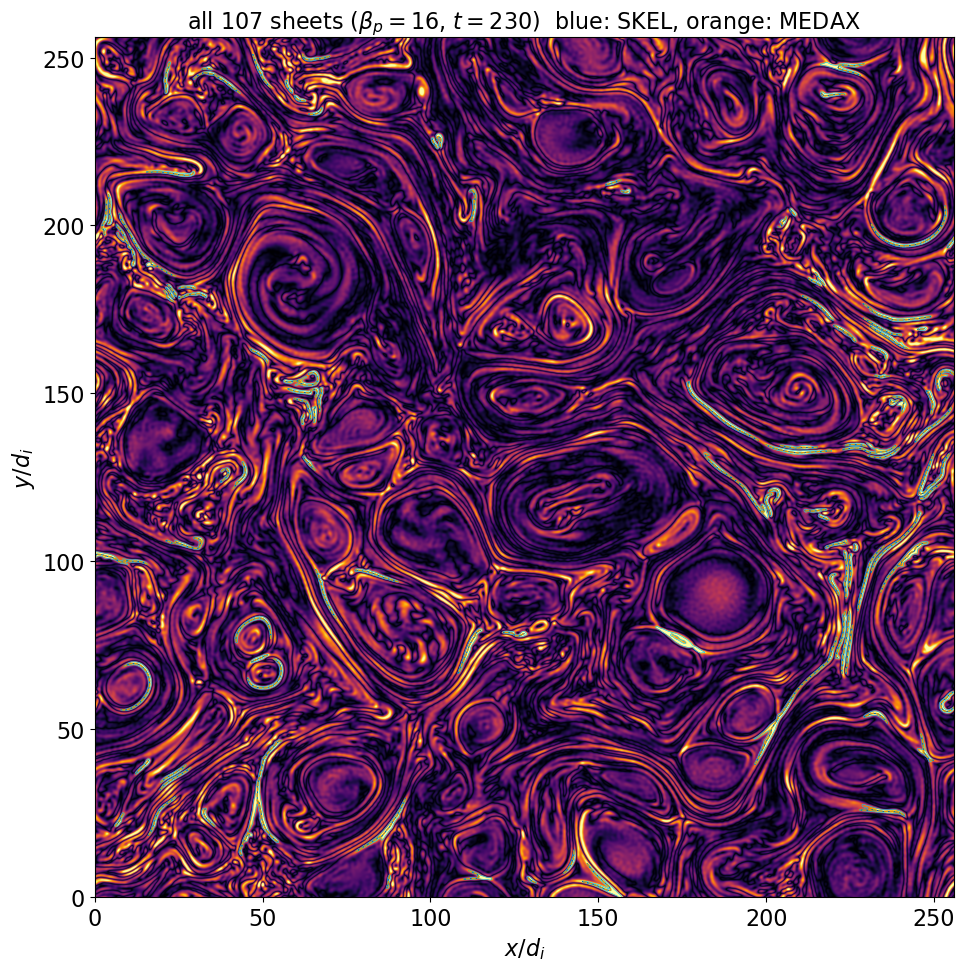

   overview: good for checking the detection; at 256 d_i across the box the two centrelines overlap, so use the montage to compare them


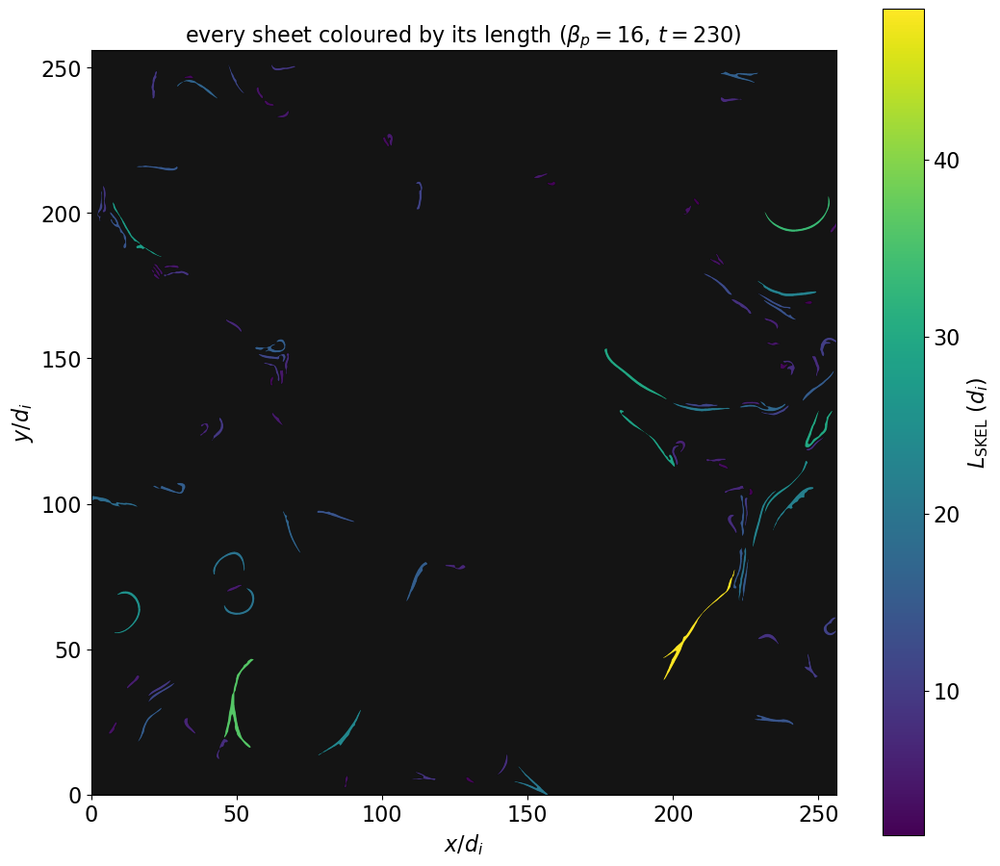

   map: blank sheets are the ones skipped as rings
   montage: 6 page(s) -> cs_length_beta16/montage_t230_page*.png
   cards: 107 -> cs_length_beta16/sheets_t230/

t=235: drawing 102 sheets


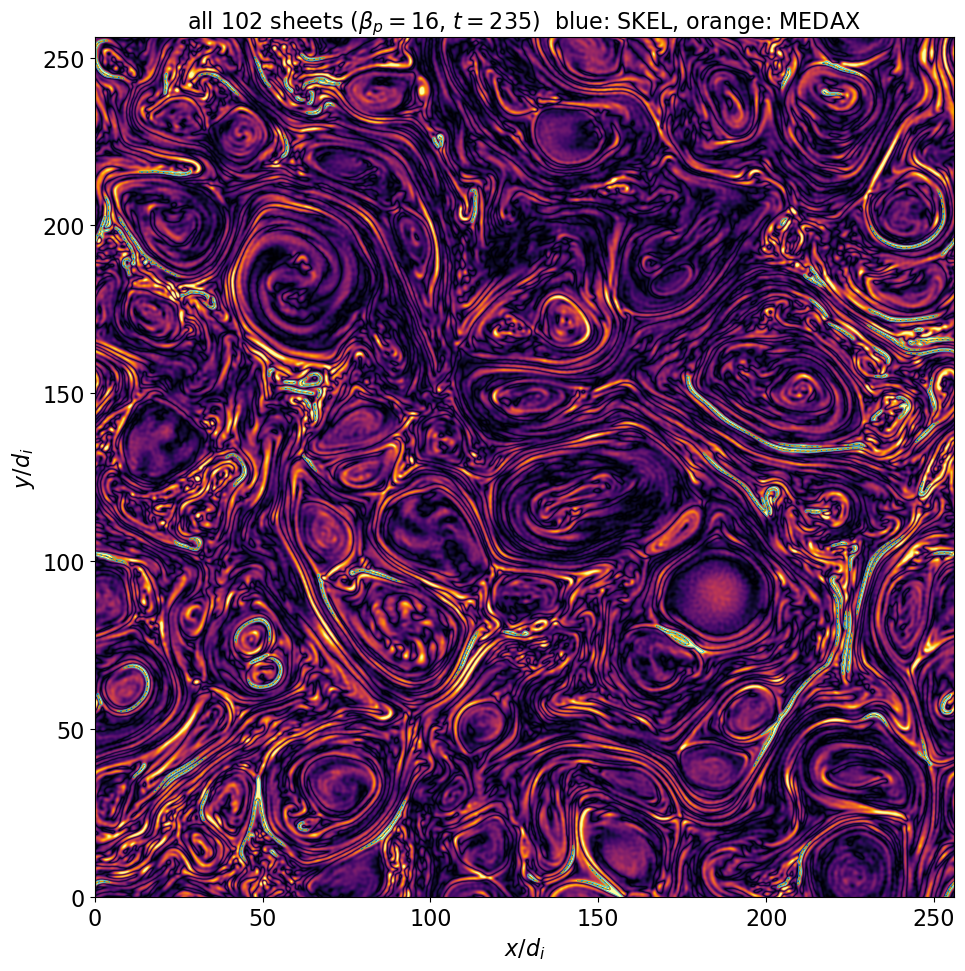

   overview: good for checking the detection; at 256 d_i across the box the two centrelines overlap, so use the montage to compare them


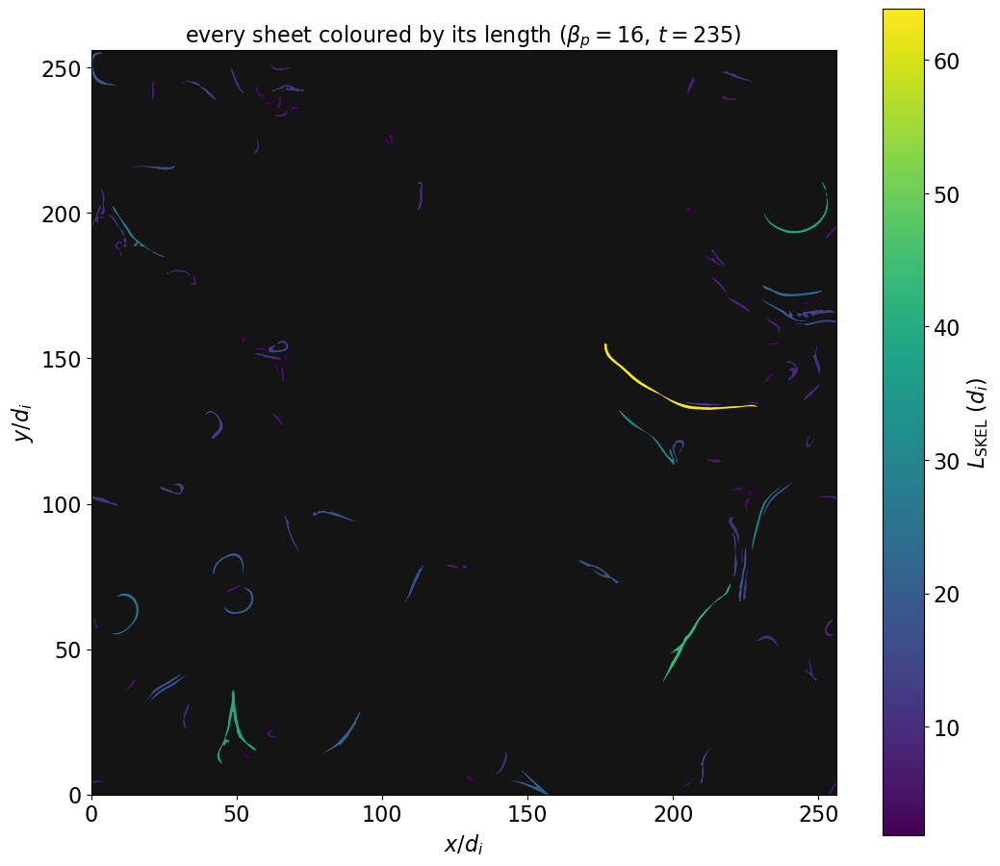

   map: blank sheets are the ones skipped as rings
   montage: 6 page(s) -> cs_length_beta16/montage_t235_page*.png
   cards: 102 -> cs_length_beta16/sheets_t235/

t=240: drawing 100 sheets


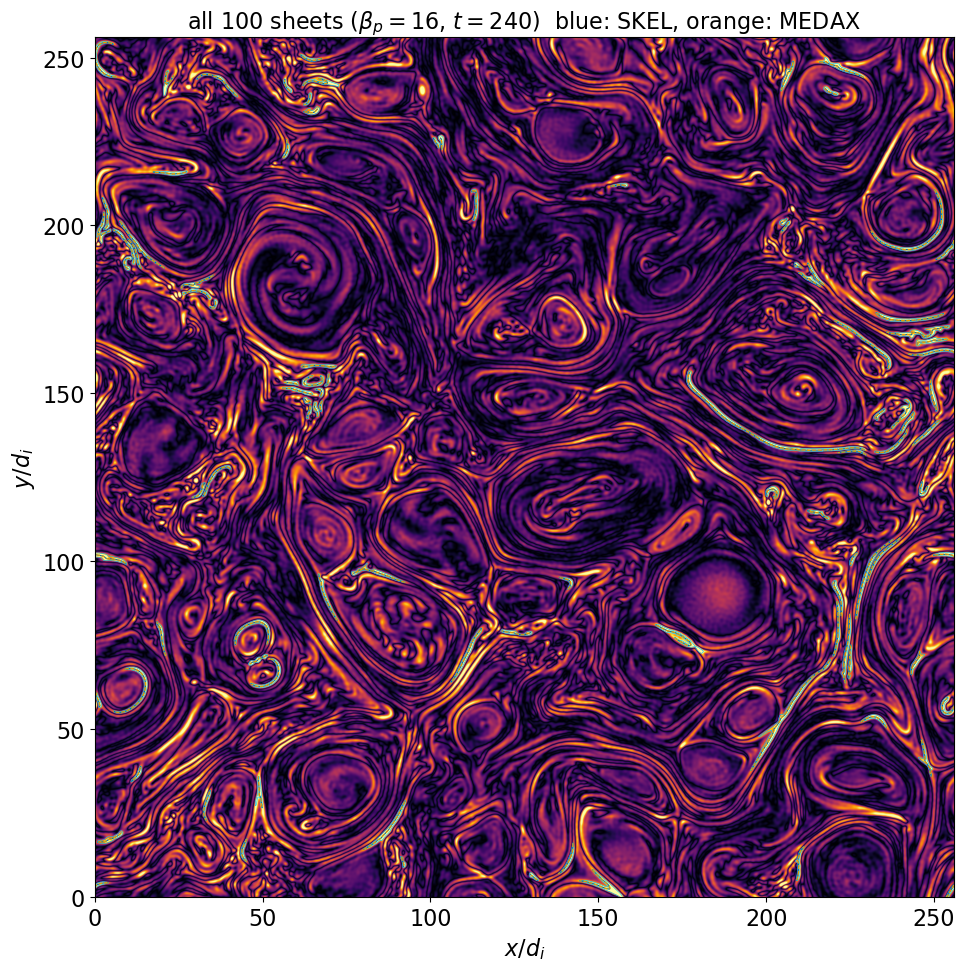

   overview: good for checking the detection; at 256 d_i across the box the two centrelines overlap, so use the montage to compare them


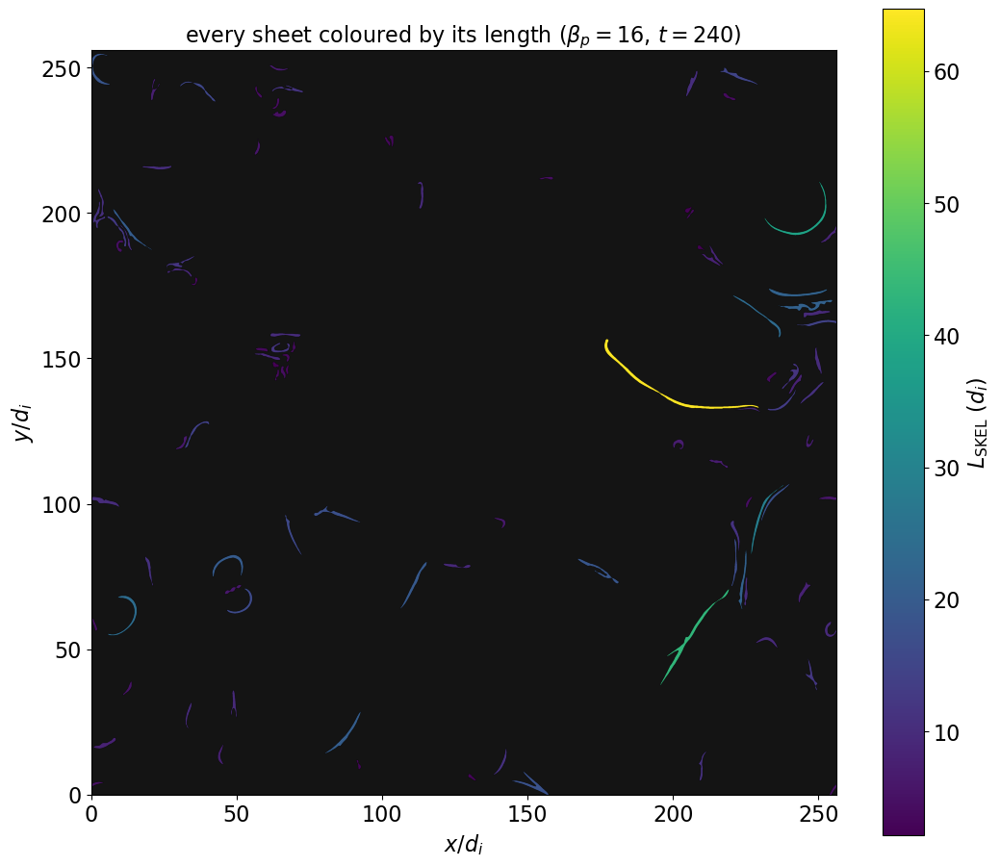

   map: blank sheets are the ones skipped as rings
   montage: 6 page(s) -> cs_length_beta16/montage_t240_page*.png
   cards: 100 -> cs_length_beta16/sheets_t240/

t=245: drawing 98 sheets


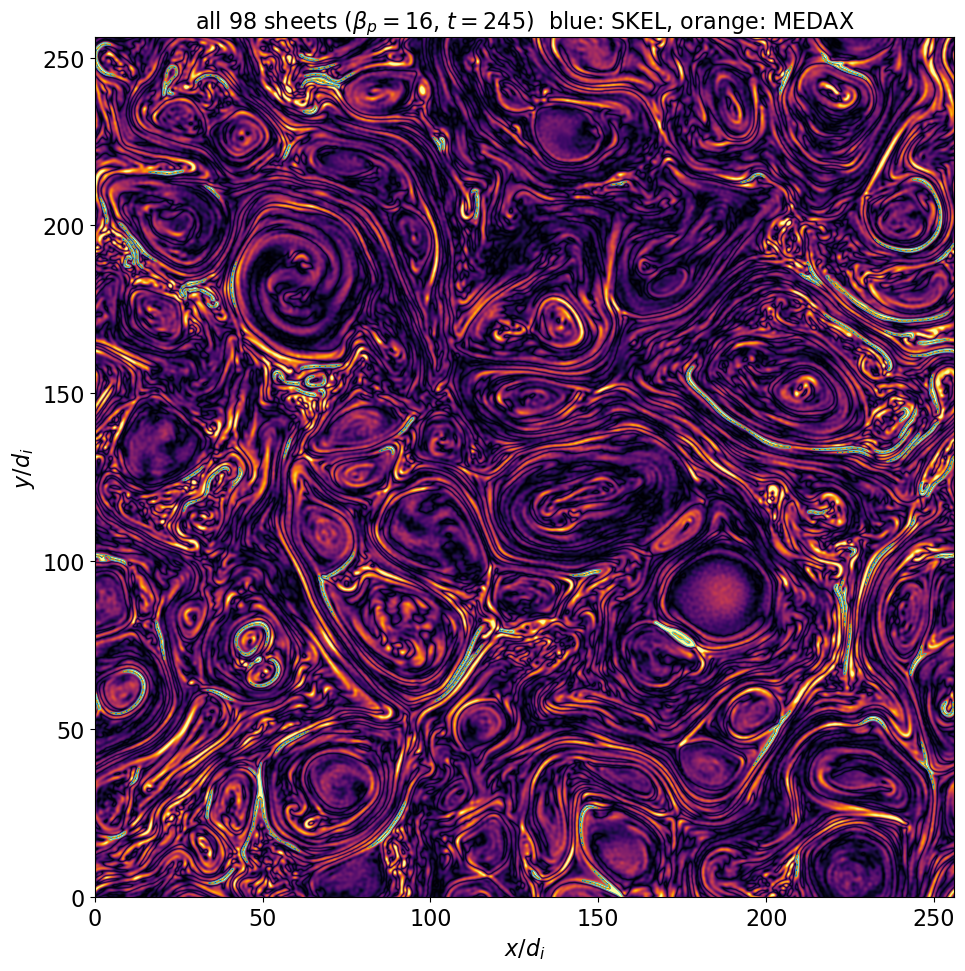

   overview: good for checking the detection; at 256 d_i across the box the two centrelines overlap, so use the montage to compare them


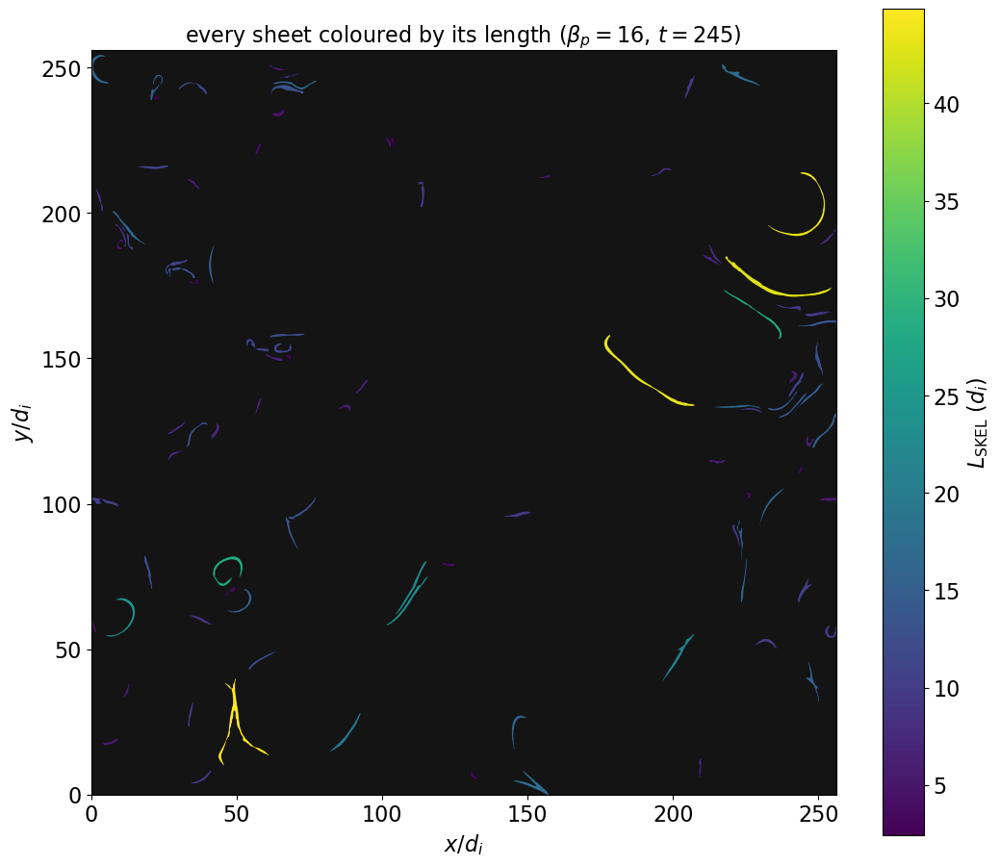

   map: blank sheets are the ones skipped as rings
   montage: 6 page(s) -> cs_length_beta16/montage_t245_page*.png
   cards: 98 -> cs_length_beta16/sheets_t245/

t=250: drawing 99 sheets


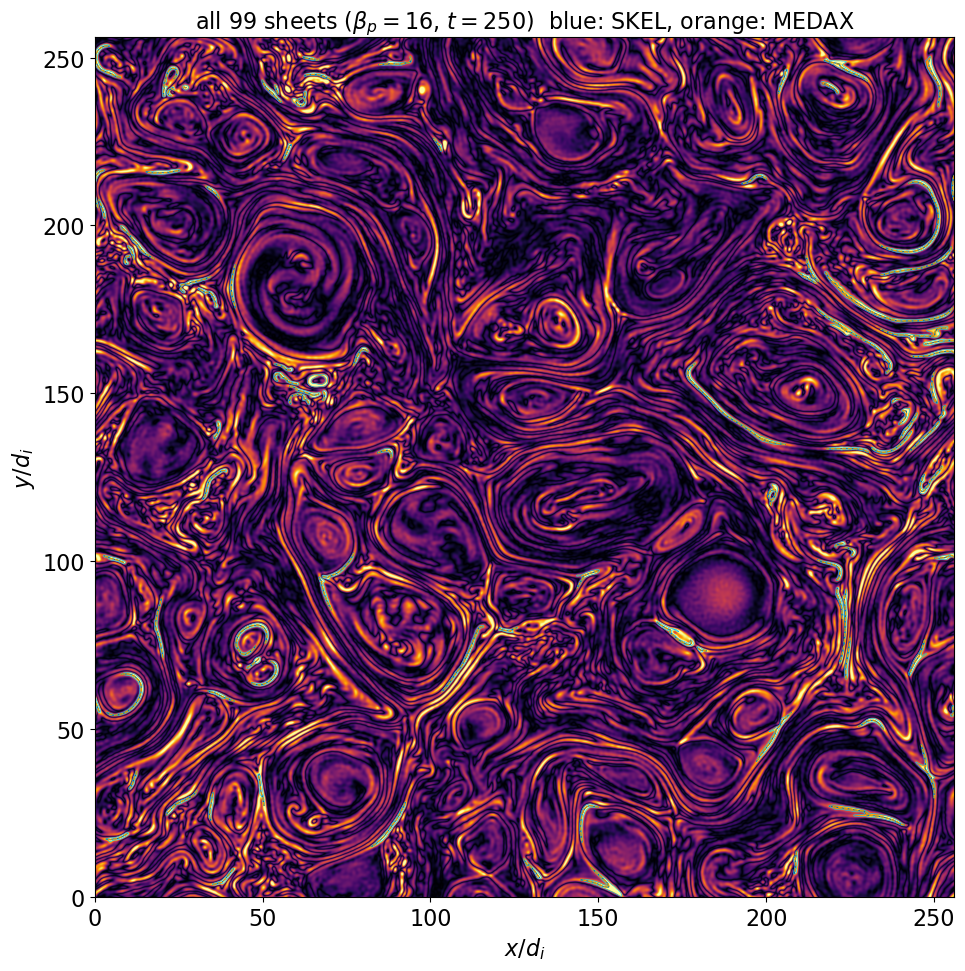

   overview: good for checking the detection; at 256 d_i across the box the two centrelines overlap, so use the montage to compare them


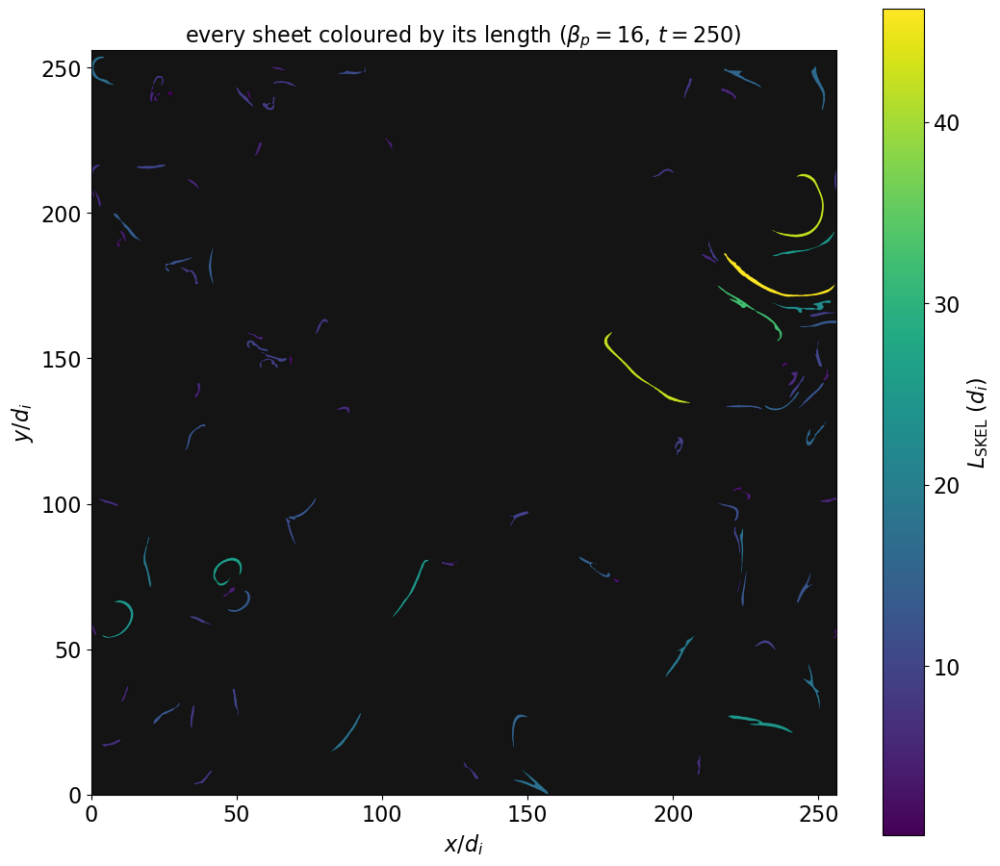

   map: blank sheets are the ones skipped as rings
   montage: 6 page(s) -> cs_length_beta16/montage_t250_page*.png
   cards: 99 -> cs_length_beta16/sheets_t250/

--- 1120 sheets, beta_p = 16 ---
length, SKEL  : median   9.16 d_i
length, MEDAX : median   9.27 d_i
MEDAX / SKEL  : median 1.016  (16-84%: 0.989 to 1.045)
                agree within 10%: 95%, within 25%: 99%

thickness     : typical 0.760 d_i, widest point 1.118 d_i (M1 is 1.47x the typical width)
tortuosity    : median 1.04  (curved length / straight-line distance; 1 = straight)
aspect ratio  : median 11.6  (length / typical width)

SKEL is the length to trust. MEDAX runs long because the exact middle of an
even-width sheet falls between two pixel rows, so it zigzags at 1.41 per step.

saved in cs_length_beta16/


In [18]:
# %% ==========================================================================
#  CELL 1 -- MEASURE   (run once; the slow part)
# ============================================================================
#  Measures every current sheet's LENGTH two different ways, plus its THICKNESS.
#
#  Both length methods do the same thing: find a line down the middle of the
#  sheet, then measure along it. They only differ in how the middle line is found.
#
#    SKEL   = "peeling".  Shave layers off the outside of the sheet, never
#             breaking it in two and never shortening a pointy end, until only a
#             1-pixel line survives.                        (skimage skeletonize)
#
#    MEDAX  = "biggest circles".  At each point ask "what is the biggest circle
#             centred here that still fits inside the sheet?"  The middle line is
#             where that circle touches the edge in two or more places.
#                                                          (skimage medial_axis)
#
#  THICKNESS comes free from the circles: thickness = 2 x (radius of the biggest
#  circle that fits). We read it all along the middle line, giving
#      th_med = the sheet's typical width
#      th_max = its widest point  ( = your M1 )
#  Both middle lines read the same distance map, so they give the same thickness;
#  we only record it once.
#
#  EXPECTED RESULT: MEDAX comes out ~10-20% LONGER than SKEL. For a sheet 10
#  pixels wide the true middle is at pixel 5.0, i.e. BETWEEN two pixel rows, so
#  MEDAX zigzags between them and every diagonal hop costs 1.41 instead of 1.00.
#  SKEL picks one row and stays there, so SKEL is the more faithful length.
#  Checked against shapes of known length (d_i, truth in brackets):
#      straight bar [12.50]  SKEL 11.99  MEDAX 14.29
#      semicircle   [19.63]  SKEL 20.07  MEDAX 20.72
#      branched L   [18.75]  SKEL 18.34  MEDAX 22.20
#
#  Sheets that have closed into a RING around a plasmoid are skipped: their
#  "length" would be a circumference, not an end-to-end span.
#
#  Needs from your session: iterative_filtering3D, partial_x_fft,
#                           partial_y_fft, detect_current_sheets
# ============================================================================

import os
import csv
import numpy as np
import h5py
from skimage import morphology, measure
from skimage.morphology import skeletonize, medial_axis
from scipy import ndimage as ndi
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

# -----------------------------
# SETTINGS
# -----------------------------
beta      = 16                        # 0.0625, 0.25, 1, 4, 16
TIMES     = list(range(200, 251, 5))    # snapshots to pool together
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"
cache_dir = str(CACHE / "filtered_cache_Jz")
out_dir   = str(RESULTS / f"cs_length_beta{beta}")

STEP          = 1 / 16.0     # one pixel, in units of d_i
MAX_HOLE_AREA = 20           # a hole bigger than this means the sheet rings a plasmoid
N_WORKERS     = min(len(TIMES), os.cpu_count() or 1)

# Snapshots kept whole in memory, so CELL 2 can draw pictures of every sheet in them.
# Each one costs about 100 MB, so keep this list short -- one snapshot is usually plenty
# to check that the centrelines are behaving.
VIS_TIMES = TIMES

os.makedirs(cache_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)

# the 8 neighbours of a pixel
NEIGHBOURS = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]

FILTER_PARAMS = {0.0625: (3, 2.0), 0.25: (3, 2.3), 1: (3, 2.5), 4: (3, 2.7), 16: (3, 3.0)}


# ============================================================
# STEP A -- three small geometry helpers
# ============================================================
def centreline_length(centreline):
    """Length of a middle line = the longest path you can walk along it.

    Think of the middle-line pixels as beads on a chain. Walk from any bead to
    the farthest one you can reach; then from THERE walk to the farthest again.
    That second distance is the length. (Side branches take care of themselves:
    a path cannot double back, so it never wanders up a branch and returns.)

    Returns (length in d_i, the pixels along that path).
    """
    beads = np.argwhere(centreline)
    if len(beads) < 2:
        return 0.0, beads

    # join each bead to its neighbours: 1 pixel for a straight step, 1.41 diagonal
    number_at = {(i, j): n for n, (i, j) in enumerate(beads)}
    starts, ends, costs = [], [], []
    for n, (i, j) in enumerate(beads):
        for di, dj in NEIGHBOURS:
            m = number_at.get((i + di, j + dj))
            if m is not None:
                starts.append(n); ends.append(m); costs.append(np.hypot(di, dj) * STEP)
    chain = csr_matrix((costs, (starts, ends)), shape=(len(beads), len(beads)))

    # walk 1: from bead 0, find the farthest bead
    far = dijkstra(chain, indices=0, directed=False)
    one_end = int(np.argmax(np.where(np.isinf(far), -1, far)))

    # walk 2: from there, find the farthest bead -- that distance is the length
    far, came_from = dijkstra(chain, indices=one_end, directed=False,
                              return_predecessors=True)
    other_end = int(np.argmax(np.where(np.isinf(far), -1, far)))

    # retrace the path, hopping backwards from one end to the other
    path, bead = [], other_end
    while bead >= 0:
        path.append(bead)
        bead = int(came_from[bead])
    return float(far[other_end]), beads[path[::-1]]


def measure_sheet(region):
    """Measure ONE sheet. Returns None for sheets we want to skip."""
    sheet, offset = crop_with_border(region, return_offset=True)

    # Skip rings. A ring is a sheet that has closed right around a plasmoid, so
    # it has no ends and its "length" would be a circumference. Test: fill in any
    # holes and see whether that changed the shape much.
    filled = ndi.binary_fill_holes(sheet)
    if filled.sum() - sheet.sum() > MAX_HOLE_AREA:
        return None
    sheet = filled              # tiny pinholes from the thresholding: just fill them

    # thickness map: 2 x distance to the nearest pixel outside the sheet
    thickness_map = 2.0 * ndi.distance_transform_edt(sheet) * STEP

    result, local = {"paths": {}}, {}
    for name, middle_line in (("skel",  skeletonize(sheet)),
                              ("medax", skeletonize(medial_axis(sheet)))):
        #                                ^ medial_axis can come out 2 px wide,
        #                                  so thin it to 1 px before measuring
        length, path = centreline_length(middle_line)
        result["L_" + name] = length
        local[name] = path                          # crop coordinates: for reading the map
        result["paths"][name] = path + offset       # full-frame coordinates: for drawing

    # read the thickness along the SKEL middle line (using CROP coordinates)
    path = local["skel"]
    if len(path) == 0:
        return None
    widths = thickness_map[path[:, 0], path[:, 1]]
    result["th_med"] = float(np.median(widths))     # typical width
    result["th_max"] = float(widths.max())          # widest point  ( = M1 )

    # straight-line end-to-end distance, for comparison with the curved length
    labelled = measure.label(region.astype(int), connectivity=2)
    result["caliper"] = float(measure.regionprops(labelled)[0].feret_diameter_max) * STEP
    return result


# ============================================================
# STEP B -- find the sheets in one snapshot (your usual pipeline)
# ============================================================
def find_sheets(time):
    """Returns (|J_par| field, labelled sheet mask)."""
    with h5py.File(base_path + f"Bx_ApJ_t{time}.h5", "r") as fx, \
         h5py.File(base_path + f"By_ApJ_t{time}.h5", "r") as fy, \
         h5py.File(base_path + f"Bz_ApJ_t{time}.h5", "r") as fz:
        Bx, By, Bz = fx["DS1"][:].T, fy["DS1"][:].T, fz["DS1"][:].T

    n_iter, Xi = FILTER_PARAMS[beta]
    cached = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cached):
        d = np.load(cached)
        Bxf, Byf, Bzf = d["Bx"], d["By"], d["Bz"]
    else:
        Bxf, Byf, Bzf = iterative_filtering3D(Bx, By, Bz, n_iter, Xi=Xi)
        np.savez_compressed(cached, Bx=Bxf, By=Byf, Bz=Bzf)

    J_par = np.abs(partial_x_fft(Byf, STEP) - partial_y_fft(Bxf, STEP))

    mask = np.zeros_like(J_par)
    for sheet in detect_current_sheets(J_par):
        for (i, j) in sheet:
            mask[i, j] = 1
    disk = morphology.disk(1)
    mask = morphology.binary_opening(mask, disk)
    mask = morphology.binary_closing(mask, disk)
    mask = morphology.remove_small_objects(mask.astype(bool), min_size=500)
    return J_par, measure.label(mask, connectivity=2)


def measure_snapshot(time):
    """Measure every sheet in one snapshot. Returns (rows, extras)."""
    J_par, labelled = find_sheets(time)
    rows, paths = [], {}
    for k in range(1, int(labelled.max()) + 1):
        r = measure_sheet(labelled == k)
        if r is None:
            continue                      # a ring, or too small to have a middle line
        rows.append([time, k, r["L_skel"], r["L_medax"], r["caliper"],
                     r["th_med"], r["th_max"]])
        paths[k] = r["paths"]

    # keep this snapshot whole if we want to draw pictures of it later
    extras = None
    if time in VIS_TIMES:
        extras = (J_par.astype(np.float32), labelled.astype(np.int16), paths)
    return time, rows, extras


COLUMNS = ["time", "sheet", "L_skel", "L_medax", "caliper", "th_med", "th_max"]


# ============================================================
# STEP C -- run every snapshot, pool the results, save
# ============================================================
all_rows, kept = [], {}          # kept[time] = (|J_par|, labelled mask, centreline paths)
print(f"measuring {len(TIMES)} snapshots on {N_WORKERS} workers ...", flush=True)
with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=mp.get_context("fork")) as pool:
    jobs = {pool.submit(measure_snapshot, t): t for t in TIMES}
    for job in as_completed(jobs):
        try:
            time, rows, extras = job.result()
            all_rows += rows
            if extras is not None:
                kept[time] = extras
            print(f"  t={time}: {len(rows)} sheets", flush=True)
        except FileNotFoundError:
            print(f"  t={jobs[job]}: file missing, skipped", flush=True)

if not all_rows:
    raise SystemExit("no sheets measured -- check the paths and TIMES")

data  = np.array(all_rows, float)
times = sorted(set(data[:, 0].astype(int).tolist()))
print(f"\npooled {len(data)} sheets from {len(times)} snapshots")

np.savez_compressed(f"{out_dir}/lengths_beta{beta}.npz", data=data,
                    cols=np.array(COLUMNS), times=np.array(times),
                    beta=beta, step=STEP)      # so CELL 2 never has to redefine them
with open(f"{out_dir}/lengths_beta{beta}.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(COLUMNS); w.writerows(data.tolist())
print(f"saved -> {out_dir}/lengths_beta{beta}.npz (+ .csv)")


# %% ==========================================================================
#  CELL 2 -- PLOT   (re-run as often as you like; nothing is recomputed)
# ============================================================================

import os
import glob
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 16})
BLUE, ORANGE = "#0072B2", "#E69F00"        # blue = SKEL, orange = MEDAX

# --- which pictures to draw (see the "Pictures" section at the bottom) ---
DRAW_OVERVIEW = True      # the whole box: where the sheets are + every centreline
DRAW_MAP      = True      # the whole box: each sheet coloured by its measured length
DRAW_MONTAGE  = True      # every sheet as a small panel, several pages of them
CARDS         = "all"   # one big PNG per sheet: "all", "worst", or "none"
SHOW_OUTLINES = True      # trace the detected sheet edge (white) and its neighbours (grey)
N_WORST       = 12        # how many, when CARDS = "worst"
MONTAGE_GRID  = (3, 6)    # (columns, rows) per montage page

# beta is set ONCE, in CELL 1. If CELL 1 has run in this session its variables are
# still here; if the kernel was restarted we reload the newest results file and take
# beta, out_dir and STEP from inside it -- so there is nothing to keep in sync.
try:
    data
except NameError:
    found = glob.glob("cs_length_beta*/lengths_beta*.npz")
    if not found:
        raise SystemExit("no saved results found -- run CELL 1 first")
    newest = max(found, key=os.path.getmtime)
    d = np.load(newest, allow_pickle=True)
    data, COLUMNS, times = d["data"], list(d["cols"]), d["times"].tolist()
    beta, STEP = d["beta"].item(), d["step"].item()
    out_dir, kept = os.path.dirname(newest), {}
    print(f"loaded {newest}  (beta_p = {beta})")

col      = {name: i for i, name in enumerate(COLUMNS)}
L_skel   = data[:, col["L_skel"]]
L_medax  = data[:, col["L_medax"]]
caliper  = data[:, col["caliper"]]
th_med   = data[:, col["th_med"]]
th_max   = data[:, col["th_max"]]
ratio    = L_medax / L_skel
print(f"{len(data)} sheets (rings were already skipped in CELL 1)")

fig, ax = plt.subplots(2, 2, figsize=(15, 12))

# --- how long are the sheets, by each method? ---
bins = np.logspace(np.log10(min(L_skel.min(), L_medax.min())),
                   np.log10(max(L_skel.max(), L_medax.max())), 30)
for arr, colour, name in ((L_skel, BLUE, "SKEL (peeling)"),
                          (L_medax, ORANGE, "MEDAX (biggest circles)")):
    ax[0, 0].hist(arr, bins=bins, density=True, histtype="step", lw=2.5, color=colour,
                  label=f"{name}\nmedian = {np.median(arr):.2f} $d_i$")
    ax[0, 0].axvline(np.median(arr), color=colour, ls=":", lw=1.5)
ax[0, 0].set_xscale("log"); ax[0, 0].legend()
ax[0, 0].set_xlabel(r"length $(d_i)$"); ax[0, 0].set_ylabel("PDF")
ax[0, 0].set_title("how long are the sheets?")

# --- do the two methods agree, sheet by sheet? ---
ax[0, 1].scatter(L_skel, L_medax, s=10, alpha=0.35, color=BLUE)
lim = [min(L_skel.min(), L_medax.min()), max(L_skel.max(), L_medax.max())]
ax[0, 1].plot(lim, lim, "k--", lw=1.5, label="if they agreed exactly")
ax[0, 1].plot(lim, [np.median(ratio) * v for v in lim], ":", color=ORANGE, lw=2,
              label=f"actual: MEDAX {np.median(ratio):.2f}x longer")
ax[0, 1].set_xscale("log"); ax[0, 1].set_yscale("log")
ax[0, 1].set_xlim(lim); ax[0, 1].set_ylim(lim); ax[0, 1].legend(loc="upper left")
ax[0, 1].set_xlabel(r"$L_{\rm SKEL}$ $(d_i)$"); ax[0, 1].set_ylabel(r"$L_{\rm MEDAX}$ $(d_i)$")
ax[0, 1].set_title("sheet-by-sheet agreement")

# --- by how much do they disagree? (MEDAX runs long: the zigzag) ---
ax[1, 0].hist(ratio, bins=np.linspace(ratio.min(), ratio.max(), 30),
              color=ORANGE, alpha=0.55, edgecolor="black")
ax[1, 0].axvline(np.median(ratio), color="k", ls="--", lw=2,
                 label=f"median = {np.median(ratio):.3f}")
ax[1, 0].axvline(1.0, color=BLUE, ls=":", lw=2, label="exact agreement")
ax[1, 0].set_xlabel(r"$L_{\rm MEDAX}/L_{\rm SKEL}$"); ax[1, 0].set_ylabel("sheets")
ax[1, 0].set_title("MEDAX runs long (zigzag)"); ax[1, 0].legend()

# --- thickness: typical width vs widest point ---
tb = np.logspace(np.log10(th_med.min()), np.log10(th_max.max()), 30)
ax[1, 1].hist(th_max, bins=tb, density=True, histtype="step", lw=2.5, color="0.35",
              label=f"widest point (= M1)\nmedian = {np.median(th_max):.3f} $d_i$")
ax[1, 1].hist(th_med, bins=tb, density=True, histtype="step", lw=2.5, color=BLUE,
              label=f"typical width\nmedian = {np.median(th_med):.3f} $d_i$")
ax[1, 1].set_xscale("log"); ax[1, 1].legend()
ax[1, 1].set_xlabel(r"thickness $(d_i)$"); ax[1, 1].set_ylabel("PDF")
ax[1, 1].set_title("thickness along the middle line")

span = f"t={times[0]}" if len(times) == 1 else f"t={times[0]}$-${times[-1]}"
fig.suptitle(rf"CS length: two middle-line methods  ($\beta_p={beta}$, $\beta_e=1$, "
             rf"{span}, N={len(data)})", y=1.00)
fig.tight_layout()
fig.savefig(f"{out_dir}/comparison_beta{beta}.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# Pictures of the sheets
#   overview : the whole box, every sheet outlined, both centrelines drawn
#   map      : the whole box, each sheet filled with its measured length
#   montage  : every sheet as a small panel, a few pages of them  <- browse them all
#   cards    : one big PNG per sheet ("all" is fine but makes hundreds of files)
# ============================================================
def crop_box(labelled, k, pad=15):
    """Pixel window around sheet k, with a little padding."""
    xs, ys = np.where(labelled == k)
    return (max(0, xs.min() - pad), min(labelled.shape[0], xs.max() + pad + 1),
            max(0, ys.min() - pad), min(labelled.shape[1], ys.max() + pad + 1))


def draw_outline(axis, mask_crop, colour, lw, origin=(0.0, 0.0)):
    """Trace the edge of a mask in d_i, lined up with an image drawn from the same crop.
    This is the DETECTED sheet boundary -- the |J_par| glow spreads out past it, so
    without this line you cannot see where the detection actually put the edge."""
    nx, ny = mask_crop.shape
    xs = (np.arange(nx) + 0.5) * STEP + origin[0]
    ys = (np.arange(ny) + 0.5) * STEP + origin[1]
    axis.contour(*np.meshgrid(xs, ys), mask_crop.T, levels=[0.5],
                 colors=colour, linewidths=lw)


def draw_centrelines(axis, paths_k, x_off=0, y_off=0, lw=2.0, labels=None):
    """Draw the SKEL and MEDAX middle lines on an axis, in d_i."""
    for name, colour, style in (("skel", BLUE, "-"), ("medax", ORANGE, "--")):
        p = paths_k.get(name)
        if p is not None and len(p) > 1:
            axis.plot((p[:, 0] - x_off) * STEP, (p[:, 1] - y_off) * STEP, style,
                      color=colour, lw=lw,
                      label=None if labels is None else labels[name])


if not kept:
    print("no snapshots kept in memory -- re-run CELL 1 to draw pictures "
          "(set VIS_TIMES there to choose which)")

for t, (J_par, labelled, paths) in sorted(kept.items()):
    here = data[:, col["time"]] == t
    rows_t = data[here]
    ratio_t = ratio[here]
    n_sheets = len(rows_t)
    print(f"\nt={t}: drawing {n_sheets} sheets")
    Nx, Ny = J_par.shape

    # ---------- 1. overview: the whole box ----------
    if DRAW_OVERVIEW:
        fig, a = plt.subplots(figsize=(11, 10))
        a.imshow(J_par.T, origin="lower", cmap="inferno", extent=[0, Nx*STEP, 0, Ny*STEP],
                 vmax=float(np.percentile(J_par, 99)))
        xc = (np.arange(Nx) + 0.5) * STEP
        yc = (np.arange(Ny) + 0.5) * STEP
        a.contour(*np.meshgrid(xc, yc), (labelled > 0).T, levels=[0.5],
                  colors="deepskyblue", linewidths=0.4)
        for k in paths:
            draw_centrelines(a, paths[k], lw=0.8)
        a.set_xlim(0, Nx*STEP); a.set_ylim(0, Ny*STEP)
        a.set_xlabel(r"$x/d_i$"); a.set_ylabel(r"$y/d_i$")
        a.set_title(rf"all {n_sheets} sheets ($\beta_p={beta}$, $t={t}$)  "
                    "blue: SKEL, orange: MEDAX")
        fig.tight_layout()
        fig.savefig(f"{out_dir}/overview_t{t}.png", dpi=250, bbox_inches="tight")
        plt.show()
        print("   overview: good for checking the detection; at 256 d_i across the box"
              " the two centrelines overlap, so use the montage to compare them")

    # ---------- 2. map: each sheet filled with its measured length ----------
    if DRAW_MAP:
        by_label = np.full(int(labelled.max()) + 1, np.nan)
        for r_ in rows_t:
            by_label[int(r_[col["sheet"]])] = r_[col["L_skel"]]
        picture = np.where(labelled > 0, by_label[np.clip(labelled, 0, None)], np.nan)
        fig, a = plt.subplots(figsize=(11, 9.5))
        a.set_facecolor("0.08")
        im = a.imshow(picture.T, origin="lower", cmap="viridis",
                      extent=[0, Nx*STEP, 0, Ny*STEP])
        fig.colorbar(im, ax=a, label=r"$L_{\rm SKEL}$ $(d_i)$")
        a.set_xlabel(r"$x/d_i$"); a.set_ylabel(r"$y/d_i$")
        a.set_title(rf"every sheet coloured by its length ($\beta_p={beta}$, $t={t}$)")
        fig.tight_layout()
        fig.savefig(f"{out_dir}/map_length_t{t}.png", dpi=250, bbox_inches="tight")
        plt.show()
        print("   map: blank sheets are the ones skipped as rings")

    # ---------- 3. montage: every sheet, longest first, a few per page ----------
    if DRAW_MONTAGE and n_sheets:
        ncol, nrow = MONTAGE_GRID
        per_page = ncol * nrow
        order = np.argsort(-rows_t[:, col["L_skel"]])          # longest first
        pages = int(np.ceil(len(order) / per_page))
        for page in range(pages):
            chunk = order[page*per_page:(page+1)*per_page]
            fig, axes = plt.subplots(nrow, ncol, figsize=(5*ncol, 2.6*nrow))
            for a, i in zip(np.ravel(axes), chunk):
                k = int(rows_t[i, col["sheet"]])
                if k not in paths:
                    a.axis("off"); continue
                x0, x1, y0, y1 = crop_box(labelled, k)
                a.imshow(J_par[x0:x1, y0:y1].T, origin="lower", cmap="inferno",
                         extent=[0, (x1-x0)*STEP, 0, (y1-y0)*STEP],
                         vmax=float(np.percentile(J_par[x0:x1, y0:y1], 99.5)),
                         aspect="equal")
                if SHOW_OUTLINES:
                    patch = labelled[x0:x1, y0:y1]
                    draw_outline(a, patch == k, "white", 0.9)          # this sheet
                    others = (patch > 0) & (patch != k)
                    if others.any():
                        draw_outline(a, others, "0.55", 0.5)           # neighbours
                draw_centrelines(a, paths[k], x_off=x0, y_off=y0, lw=1.4)
                a.set_title(f"#{k}  L={rows_t[i, col['L_skel']]:.1f}  "
                            f"ratio {ratio_t[i]:.2f}", fontsize=10)
                a.set_xticks([]); a.set_yticks([])
            for a in np.ravel(axes)[len(chunk):]:
                a.axis("off")
            fig.suptitle(rf"$\beta_p={beta}$, $t={t}$ -- sheets {page*per_page+1}"
                         rf"-{min((page+1)*per_page, len(order))} of {len(order)}, "
                         "longest first   (blue SKEL, orange MEDAX)", y=1.00)
            fig.tight_layout()
            fig.savefig(f"{out_dir}/montage_t{t}_page{page+1:02d}.png", dpi=150,
                        bbox_inches="tight")
            plt.close(fig)
        print(f"   montage: {pages} page(s) -> {out_dir}/montage_t{t}_page*.png")

    # ---------- 4. one big PNG per sheet ----------
    if CARDS != "none" and n_sheets:
        if CARDS == "all":
            chosen = np.arange(n_sheets)
        else:
            chosen = np.argsort(-np.abs(ratio_t - 1))[:N_WORST]   # worst disagreement
        card_dir = f"{out_dir}/sheets_t{t}"
        os.makedirs(card_dir, exist_ok=True)
        for i in chosen:
            k = int(rows_t[i, col["sheet"]])
            if k not in paths:
                continue
            x0, x1, y0, y1 = crop_box(labelled, k)
            fig, a = plt.subplots(figsize=(8, 6))
            a.imshow(J_par[x0:x1, y0:y1].T, origin="lower", cmap="inferno",
                     extent=[x0*STEP, x1*STEP, y0*STEP, y1*STEP],
                     vmax=float(np.percentile(J_par[x0:x1, y0:y1], 99.5)), aspect="equal")
            if SHOW_OUTLINES:
                patch = labelled[x0:x1, y0:y1]
                draw_outline(a, patch == k, "white", 1.2, origin=(x0*STEP, y0*STEP))
                others = (patch > 0) & (patch != k)
                if others.any():
                    draw_outline(a, others, "0.55", 0.7, origin=(x0*STEP, y0*STEP))
            draw_centrelines(a, paths[k], lw=2.2, labels={
                "skel":  f"SKEL   L={rows_t[i, col['L_skel']]:.2f}",
                "medax": f"MEDAX  L={rows_t[i, col['L_medax']]:.2f}"})
            a.set_xlabel(r"$x/d_i$"); a.set_ylabel(r"$y/d_i$")
            a.set_title(f"sheet {k}:  MEDAX/SKEL = {ratio_t[i]:.2f},  "
                        f"width {rows_t[i, col['th_med']]:.3f} $d_i$")
            a.legend(fontsize=11, loc="upper right", framealpha=0.7)
            fig.tight_layout()
            fig.savefig(f"{card_dir}/sheet_{k:03d}.png", dpi=130, bbox_inches="tight")
            plt.close(fig)
        print(f"   cards: {len(chosen)} -> {card_dir}/")


# ============================================================
# Numbers
# ============================================================
print(f"\n--- {len(data)} sheets, beta_p = {beta} ---")
print(f"length, SKEL  : median {np.median(L_skel):6.2f} d_i")
print(f"length, MEDAX : median {np.median(L_medax):6.2f} d_i")
print(f"MEDAX / SKEL  : median {np.median(ratio):.3f}  "
      f"(16-84%: {np.percentile(ratio,16):.3f} to {np.percentile(ratio,84):.3f})")
print(f"                agree within 10%: {100*np.mean(abs(ratio-1)<0.1):.0f}%, "
      f"within 25%: {100*np.mean(abs(ratio-1)<0.25):.0f}%")
print(f"\nthickness     : typical {np.median(th_med):.3f} d_i, "
      f"widest point {np.median(th_max):.3f} d_i "
      f"(M1 is {np.median(th_max)/np.median(th_med):.2f}x the typical width)")
print(f"tortuosity    : median {np.median(L_skel/caliper):.2f}  "
      f"(curved length / straight-line distance; 1 = straight)")
print(f"aspect ratio  : median {np.median(L_skel/th_med):.1f}  (length / typical width)")
print(f"\nSKEL is the length to trust. MEDAX runs long because the exact middle of an")
print(f"even-width sheet falls between two pixel rows, so it zigzags at 1.41 per step.")
print(f"\nsaved in {out_dir}/")

measuring 11 snapshots on 11 workers ...
  t=230: 209 sheets
  t=235: 217 sheets
  t=245: 214 sheets
  t=250: 211 sheets
  t=240: 222 sheets
  t=210: 220 sheets
  t=225: 207 sheets
  t=205: 227 sheets
  t=215: 228 sheets
  t=220: 229 sheets
  t=200: 253 sheets

pooled 2437 sheets from 11 snapshots
saved -> cs_length_beta0.25/lengths_beta0.25.npz (+ .csv)
2437 sheets (rings were already skipped in CELL 1)


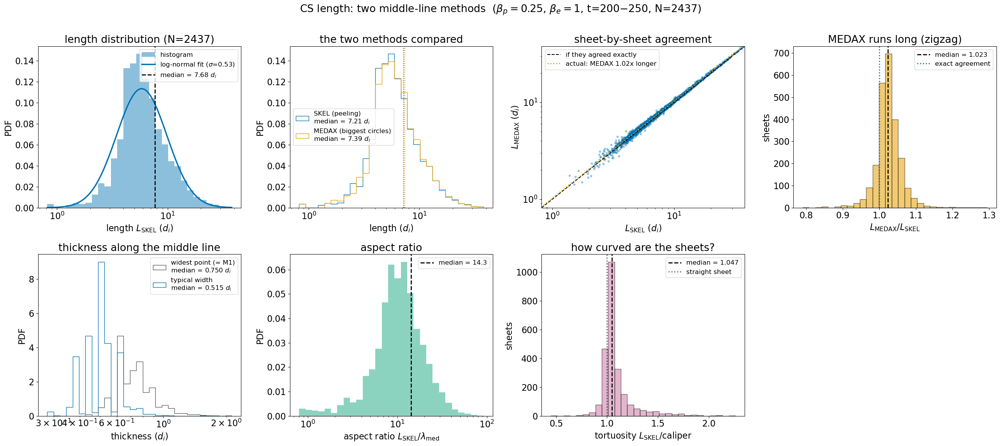


t=200: drawing 253 sheets


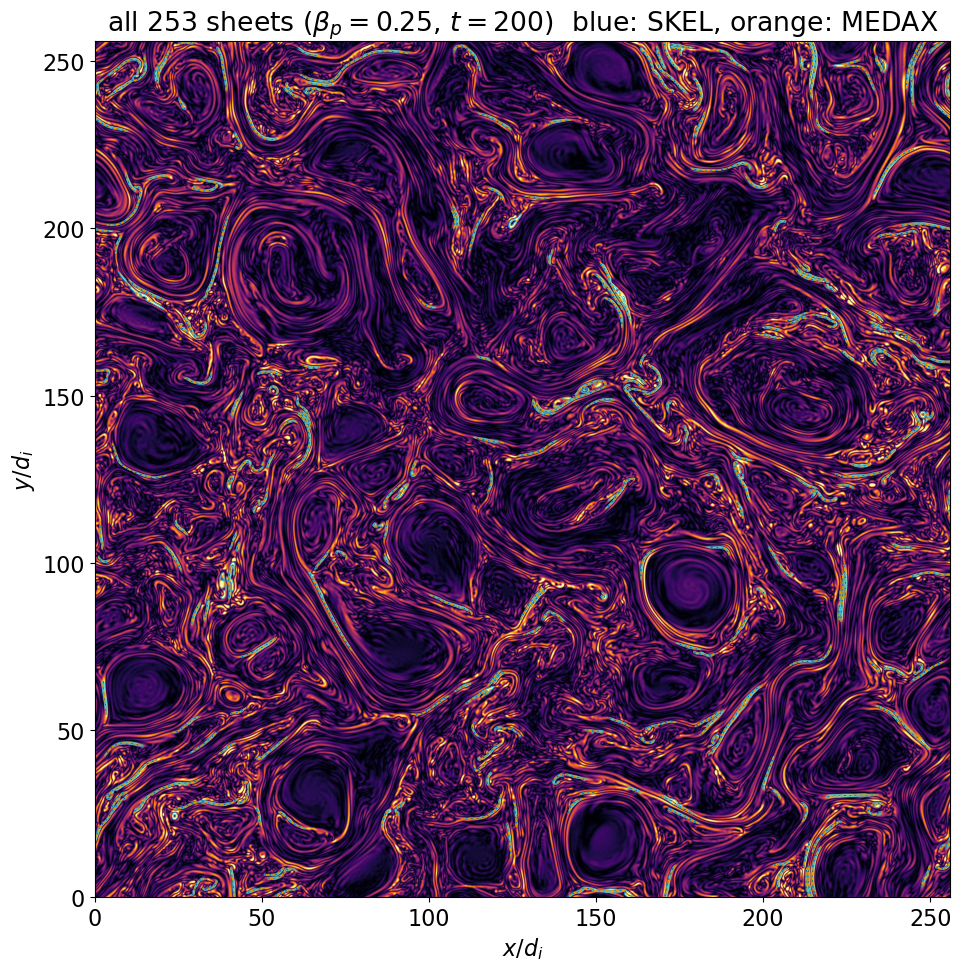

   overview: good for checking the detection; at 256 d_i across the box the two centrelines overlap, so use the montage to compare them


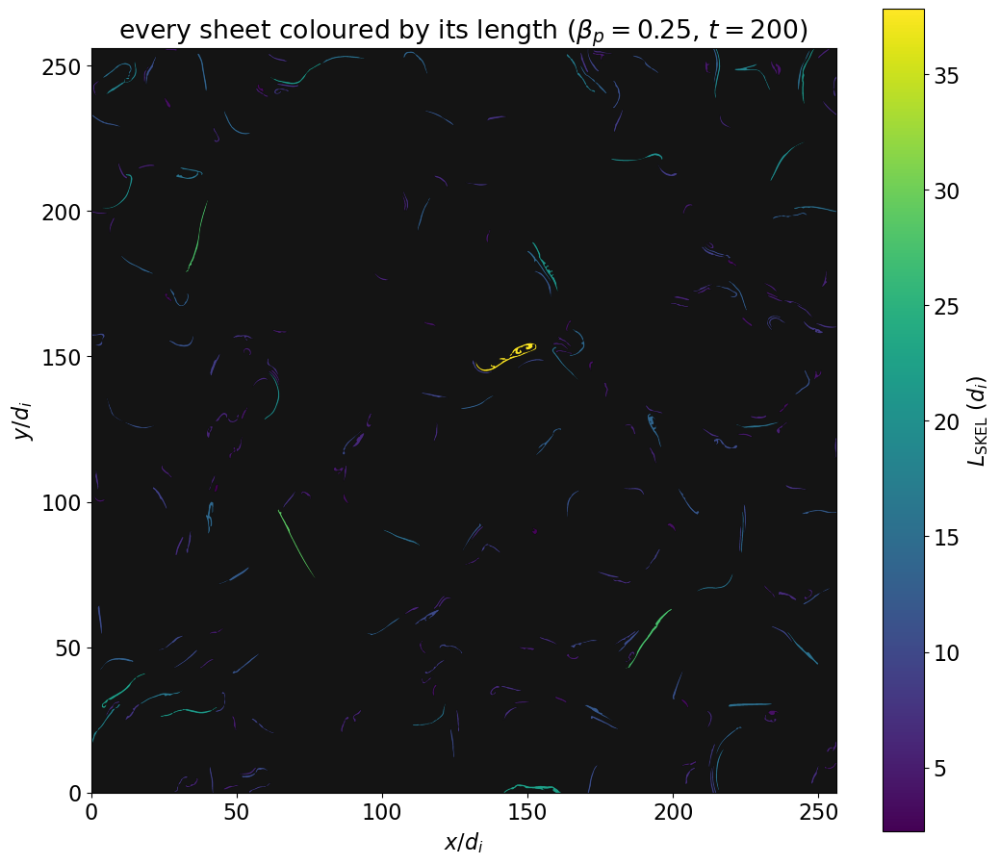

   map: blank sheets are the ones skipped as rings
   montage: 15 page(s) -> cs_length_beta0.25/montage_t200_page*.png
   cards: 12 -> cs_length_beta0.25/sheets_t200/

--- 2437 sheets, beta_p = 0.25 ---
length, SKEL  : median   7.21 d_i
length, MEDAX : median   7.39 d_i
MEDAX / SKEL  : median 1.023  (16-84%: 1.000 to 1.052)
                agree within 10%: 97%, within 25%: 100%

thickness     : typical 0.515 d_i, widest point 0.750 d_i (M1 is 1.46x the typical width)
tortuosity    : median 1.05  (curved length / straight-line distance; 1 = straight)
aspect ratio  : median 14.3  (length / typical width)

SKEL is the length to trust. MEDAX runs long because the exact middle of an
even-width sheet falls between two pixel rows, so it zigzags at 1.41 per step.

saved in cs_length_beta0.25/


In [5]:
# %% ==========================================================================
#  CELL 1 -- MEASURE   (run once; the slow part)
# ============================================================================
#  Measures every current sheet's LENGTH two different ways, plus its THICKNESS.
#
#  Both length methods do the same thing: find a line down the middle of the
#  sheet, then measure along it. They only differ in how the middle line is found.
#
#    SKEL   = "peeling".  Shave layers off the outside of the sheet, never
#             breaking it in two and never shortening a pointy end, until only a
#             1-pixel line survives.                        (skimage skeletonize)
#
#    MEDAX  = "biggest circles".  At each point ask "what is the biggest circle
#             centred here that still fits inside the sheet?"  The middle line is
#             where that circle touches the edge in two or more places.
#                                                          (skimage medial_axis)
#
#  THICKNESS comes free from the circles: thickness = 2 x (radius of the biggest
#  circle that fits). We read it all along the middle line, giving
#      th_med = the sheet's typical width
#      th_max = its widest point  ( = your M1 )
#  Both middle lines read the same distance map, so they give the same thickness;
#  we only record it once.
#
#  EXPECTED RESULT: MEDAX comes out ~10-20% LONGER than SKEL. For a sheet 10
#  pixels wide the true middle is at pixel 5.0, i.e. BETWEEN two pixel rows, so
#  MEDAX zigzags between them and every diagonal hop costs 1.41 instead of 1.00.
#  SKEL picks one row and stays there, so SKEL is the more faithful length.
#  Checked against shapes of known length (d_i, truth in brackets):
#      straight bar [12.50]  SKEL 11.99  MEDAX 14.29
#      semicircle   [19.63]  SKEL 20.07  MEDAX 20.72
#      branched L   [18.75]  SKEL 18.34  MEDAX 22.20
#
#  Sheets that have closed into a RING around a plasmoid are skipped: their
#  "length" would be a circumference, not an end-to-end span.
#
#  Needs from your session: iterative_filtering3D, partial_x_fft,
#                           partial_y_fft, detect_current_sheets
# ============================================================================

import os
import csv
import numpy as np
import h5py
from skimage import morphology, measure
from skimage.morphology import skeletonize, medial_axis
from scipy import ndimage as ndi
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

# -----------------------------
# SETTINGS
# -----------------------------
beta      = 0.25                        # 0.0625, 0.25, 1, 4, 16
TIMES     = list(range(200, 251, 5))    # snapshots to pool together
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"
cache_dir = str(CACHE / "filtered_cache_Jz")
out_dir   = str(RESULTS / f"cs_length_beta{beta}")

STEP          = 1 / 16.0     # one pixel, in units of d_i
MAX_HOLE_AREA = 20           # a hole bigger than this means the sheet rings a plasmoid
N_WORKERS     = min(len(TIMES), os.cpu_count() or 1)

# Snapshots kept whole in memory, so CELL 2 can draw pictures of every sheet in them.
# Each one costs about 100 MB, so keep this list short -- one snapshot is usually plenty
# to check that the centrelines are behaving.
VIS_TIMES = [TIMES[0]]

os.makedirs(cache_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)

# the 8 neighbours of a pixel
NEIGHBOURS = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]

FILTER_PARAMS = {0.0625: (3, 2.0), 0.25: (3, 2.3), 1: (3, 2.5), 4: (3, 2.7), 16: (3, 3.0)}


# ============================================================
# STEP A -- three small geometry helpers
# ============================================================
def measure_sheet(region):
    """Measure ONE sheet. Returns None for sheets we want to skip."""
    sheet, offset = crop_with_border(region, return_offset=True)

    # Skip rings. A ring is a sheet that has closed right around a plasmoid, so
    # it has no ends and its "length" would be a circumference. Test: fill in any
    # holes and see whether that changed the shape much.
    filled = ndi.binary_fill_holes(sheet)
    if filled.sum() - sheet.sum() > MAX_HOLE_AREA:
        return None
    sheet = filled              # tiny pinholes from the thresholding: just fill them

    # thickness map: 2 x distance to the nearest pixel outside the sheet
    thickness_map = 2.0 * ndi.distance_transform_edt(sheet) * STEP

    result, local = {"paths": {}}, {}
    for name, middle_line in (("skel",  skeletonize(sheet)),
                              ("medax", skeletonize(medial_axis(sheet)))):
        #                                ^ medial_axis can come out 2 px wide,
        #                                  so thin it to 1 px before measuring
        length, path = centreline_length(middle_line)
        result["L_" + name] = length
        local[name] = path                          # crop coordinates: for reading the map
        result["paths"][name] = path + offset       # full-frame coordinates: for drawing

    # read the thickness along the SKEL middle line (using CROP coordinates)
    path = local["skel"]
    # A compact, roughly round region can thin down to a SINGLE pixel, so it has no
    # measurable length. Drop those: a zero length would otherwise poison the
    # MEDAX/SKEL ratio, the aspect ratio and every log-spaced histogram bin.
    if len(path) < 2 or result["L_skel"] <= 0 or result["L_medax"] <= 0:
        return None
    widths = thickness_map[path[:, 0], path[:, 1]]
    result["th_med"] = float(np.median(widths))     # typical width
    result["th_max"] = float(widths.max())          # widest point  ( = M1 )

    # straight-line end-to-end distance, for comparison with the curved length
    labelled = measure.label(region.astype(int), connectivity=2)
    result["caliper"] = float(measure.regionprops(labelled)[0].feret_diameter_max) * STEP
    return result


# ============================================================
# STEP B -- find the sheets in one snapshot (your usual pipeline)
# ============================================================
COLUMNS = ["time", "sheet", "L_skel", "L_medax", "caliper", "th_med", "th_max"]


# ============================================================
# STEP C -- run every snapshot, pool the results, save
# ============================================================
all_rows, kept = [], {}          # kept[time] = (|J_par|, labelled mask, centreline paths)
print(f"measuring {len(TIMES)} snapshots on {N_WORKERS} workers ...", flush=True)
with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=mp.get_context("fork")) as pool:
    jobs = {pool.submit(measure_snapshot, t): t for t in TIMES}
    for job in as_completed(jobs):
        try:
            time, rows, extras = job.result()
            all_rows += rows
            if extras is not None:
                kept[time] = extras
            print(f"  t={time}: {len(rows)} sheets", flush=True)
        except FileNotFoundError:
            print(f"  t={jobs[job]}: file missing, skipped", flush=True)

if not all_rows:
    raise SystemExit("no sheets measured -- check the paths and TIMES")

data  = np.array(all_rows, float)
times = sorted(set(data[:, 0].astype(int).tolist()))
print(f"\npooled {len(data)} sheets from {len(times)} snapshots")

np.savez_compressed(f"{out_dir}/lengths_beta{beta}.npz", data=data,
                    cols=np.array(COLUMNS), times=np.array(times),
                    beta=beta, step=STEP)      # so CELL 2 never has to redefine them
with open(f"{out_dir}/lengths_beta{beta}.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(COLUMNS); w.writerows(data.tolist())
print(f"saved -> {out_dir}/lengths_beta{beta}.npz (+ .csv)")


# %% ==========================================================================
#  CELL 2 -- PLOT   (re-run as often as you like; nothing is recomputed)
# ============================================================================

import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import lognorm

plt.rcParams.update({"font.size": 16})
BLUE, ORANGE = "#0072B2", "#E69F00"        # blue = SKEL, orange = MEDAX

# --- which pictures to draw (see the "Pictures" section at the bottom) ---
DRAW_OVERVIEW = True      # the whole box: where the sheets are + every centreline
DRAW_MAP      = True      # the whole box: each sheet coloured by its measured length
DRAW_MONTAGE  = True      # every sheet as a small panel, several pages of them
CARDS         = "worst"   # one big PNG per sheet: "all", "worst", or "none"
SHOW_OUTLINES = True      # trace the detected sheet edge (white) and its neighbours (grey)
N_WORST       = 12        # how many, when CARDS = "worst"
MONTAGE_GRID  = (3, 6)    # (columns, rows) per montage page

# beta is set ONCE, in CELL 1. If CELL 1 has run in this session its variables are
# still here; if the kernel was restarted we reload the newest results file and take
# beta, out_dir and STEP from inside it -- so there is nothing to keep in sync.
try:
    data
except NameError:
    found = glob.glob("cs_length_beta*/lengths_beta*.npz")
    if not found:
        raise SystemExit("no saved results found -- run CELL 1 first")
    newest = max(found, key=os.path.getmtime)
    d = np.load(newest, allow_pickle=True)
    data, COLUMNS, times = d["data"], list(d["cols"]), d["times"].tolist()
    beta, STEP = d["beta"].item(), d["step"].item()
    out_dir, kept = os.path.dirname(newest), {}
    print(f"loaded {newest}  (beta_p = {beta})")

col      = {name: i for i, name in enumerate(COLUMNS)}
L_skel   = data[:, col["L_skel"]]
L_medax  = data[:, col["L_medax"]]
caliper  = data[:, col["caliper"]]
th_med   = data[:, col["th_med"]]
th_max   = data[:, col["th_max"]]
# guard against zero/non-finite lengths in older saved files (see measure_sheet)
usable = (L_skel > 0) & (L_medax > 0) & np.isfinite(L_skel) & np.isfinite(L_medax)
if not usable.all():
    print(f"dropping {int((~usable).sum())} sheet(s) with no measurable length")
    data = data[usable]
    L_skel, L_medax = L_skel[usable], L_medax[usable]
    caliper, th_med, th_max = caliper[usable], th_med[usable], th_max[usable]
ratio    = L_medax / L_skel
print(f"{len(data)} sheets (rings were already skipped in CELL 1)")

fig, ax = plt.subplots(2, 4, figsize=(26, 11.5))

# --- LENGTH histogram (SKEL, the length to trust) + lognormal fit ---
bins = np.logspace(np.log10(min(L_skel.min(), L_medax.min())),
                   np.log10(max(L_skel.max(), L_medax.max())), 30)
ax[0, 0].hist(L_skel, bins=bins, density=True, alpha=0.45, color=BLUE, label="histogram")
shape, loc, scale = lognorm.fit(L_skel[L_skel > 0], floc=0)
xs_fit = np.logspace(np.log10(bins[0]), np.log10(bins[-1]), 400)
ax[0, 0].plot(xs_fit, lognorm.pdf(xs_fit, shape, loc, scale), color=BLUE, lw=2.5,
              label=rf"log-normal fit ($\sigma$={shape:.2f})")
ax[0, 0].axvline(scale, color="k", ls="--", lw=2, label=f"median = {scale:.2f} $d_i$")
ax[0, 0].set_xscale("log"); ax[0, 0].legend(fontsize=12)
ax[0, 0].set_xlabel(r"length $L_{\rm SKEL}$ $(d_i)$"); ax[0, 0].set_ylabel("PDF")
ax[0, 0].set_title(f"length distribution (N={len(L_skel)})")

# --- how long are the sheets, by each method? ---
for arr, colour, name in ((L_skel, BLUE, "SKEL (peeling)"),
                          (L_medax, ORANGE, "MEDAX (biggest circles)")):
    ax[0, 1].hist(arr, bins=bins, density=True, histtype="step", lw=2.5, color=colour,
                  label=f"{name}\nmedian = {np.median(arr):.2f} $d_i$")
    ax[0, 1].axvline(np.median(arr), color=colour, ls=":", lw=1.5)
ax[0, 1].set_xscale("log"); ax[0, 1].legend(fontsize=12)
ax[0, 1].set_xlabel(r"length $(d_i)$"); ax[0, 1].set_ylabel("PDF")
ax[0, 1].set_title("the two methods compared")

# --- do the two methods agree, sheet by sheet? ---
ax[0, 2].scatter(L_skel, L_medax, s=10, alpha=0.35, color=BLUE)
lim = [min(L_skel.min(), L_medax.min()), max(L_skel.max(), L_medax.max())]
ax[0, 2].plot(lim, lim, "k--", lw=1.5, label="if they agreed exactly")
ax[0, 2].plot(lim, [np.median(ratio) * v for v in lim], ":", color=ORANGE, lw=2,
              label=f"actual: MEDAX {np.median(ratio):.2f}x longer")
ax[0, 2].set_xscale("log"); ax[0, 2].set_yscale("log")
ax[0, 2].set_xlim(lim); ax[0, 2].set_ylim(lim); ax[0, 2].legend(loc="upper left", fontsize=12)
ax[0, 2].set_xlabel(r"$L_{\rm SKEL}$ $(d_i)$"); ax[0, 2].set_ylabel(r"$L_{\rm MEDAX}$ $(d_i)$")
ax[0, 2].set_title("sheet-by-sheet agreement")

# --- by how much do they disagree? (MEDAX runs long: the zigzag) ---
ax[0, 3].hist(ratio, bins=np.linspace(ratio.min(), ratio.max(), 30),
              color=ORANGE, alpha=0.55, edgecolor="black")
ax[0, 3].axvline(np.median(ratio), color="k", ls="--", lw=2,
                 label=f"median = {np.median(ratio):.3f}")
ax[0, 3].axvline(1.0, color=BLUE, ls=":", lw=2, label="exact agreement")
ax[0, 3].set_xlabel(r"$L_{\rm MEDAX}/L_{\rm SKEL}$"); ax[0, 3].set_ylabel("sheets")
ax[0, 3].set_title("MEDAX runs long (zigzag)"); ax[0, 3].legend(fontsize=12)

# --- thickness: typical width vs widest point ---
tb = np.logspace(np.log10(th_med.min()), np.log10(th_max.max()), 30)
ax[1, 0].hist(th_max, bins=tb, density=True, histtype="step", lw=2.5, color="0.35",
              label=f"widest point (= M1)\nmedian = {np.median(th_max):.3f} $d_i$")
ax[1, 0].hist(th_med, bins=tb, density=True, histtype="step", lw=2.5, color=BLUE,
              label=f"typical width\nmedian = {np.median(th_med):.3f} $d_i$")
ax[1, 0].set_xscale("log"); ax[1, 0].legend(fontsize=12)
ax[1, 0].set_xlabel(r"thickness $(d_i)$"); ax[1, 0].set_ylabel("PDF")
ax[1, 0].set_title("thickness along the middle line")

# --- aspect ratio = length / typical width (added to fill the grid; delete if unwanted) ---
aspect = L_skel / th_med
ab = np.logspace(np.log10(aspect.min()), np.log10(aspect.max()), 30)
ax[1, 1].hist(aspect, bins=ab, density=True, alpha=0.45, color="#009E73")
ax[1, 1].axvline(np.median(aspect), color="k", ls="--", lw=2,
                 label=f"median = {np.median(aspect):.1f}")
ax[1, 1].set_xscale("log"); ax[1, 1].legend(fontsize=12)
ax[1, 1].set_xlabel(r"aspect ratio $L_{\rm SKEL}/\lambda_{\rm med}$")
ax[1, 1].set_ylabel("PDF")
ax[1, 1].set_title("aspect ratio")

# --- tortuosity = curved length / straight-line distance (1 = perfectly straight) ---
tortuosity = L_skel / caliper
ax[1, 2].hist(tortuosity, bins=np.linspace(tortuosity.min(), tortuosity.max(), 30),
              color="#CC79A7", alpha=0.55, edgecolor="black")
ax[1, 2].axvline(np.median(tortuosity), color="k", ls="--", lw=2,
                 label=f"median = {np.median(tortuosity):.3f}")
ax[1, 2].axvline(1.0, color="0.35", ls=":", lw=2, label="straight sheet")
ax[1, 2].set_xlabel(r"tortuosity $L_{\rm SKEL}/$caliper")
ax[1, 2].set_ylabel("sheets")
ax[1, 2].set_title("how curved are the sheets?"); ax[1, 2].legend(fontsize=12)

ax[1, 3].axis("off")        # spare slot -- drop the next diagnostic in here

span = f"t={times[0]}" if len(times) == 1 else f"t={times[0]}$-${times[-1]}"
fig.suptitle(rf"CS length: two middle-line methods  ($\beta_p={beta}$, $\beta_e=1$, "
             rf"{span}, N={len(data)})", y=1.00)
fig.tight_layout()
fig.savefig(f"{out_dir}/comparison_beta{beta}.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# Pictures of the sheets
#   overview : the whole box, every sheet outlined, both centrelines drawn
#   map      : the whole box, each sheet filled with its measured length
#   montage  : every sheet as a small panel, a few pages of them  <- browse them all
#   cards    : one big PNG per sheet ("all" is fine but makes hundreds of files)
# ============================================================
if not kept:
    print("no snapshots kept in memory -- re-run CELL 1 to draw pictures "
          "(set VIS_TIMES there to choose which)")

for t, (J_par, labelled, paths) in sorted(kept.items()):
    here = data[:, col["time"]] == t
    rows_t = data[here]
    ratio_t = ratio[here]
    n_sheets = len(rows_t)
    print(f"\nt={t}: drawing {n_sheets} sheets")
    Nx, Ny = J_par.shape

    # ---------- 1. overview: the whole box ----------
    if DRAW_OVERVIEW:
        fig, a = plt.subplots(figsize=(11, 10))
        a.imshow(J_par.T, origin="lower", cmap="inferno", extent=[0, Nx*STEP, 0, Ny*STEP],
                 vmax=float(np.percentile(J_par, 99)))
        xc = (np.arange(Nx) + 0.5) * STEP
        yc = (np.arange(Ny) + 0.5) * STEP
        a.contour(*np.meshgrid(xc, yc), (labelled > 0).T, levels=[0.5],
                  colors="deepskyblue", linewidths=0.4)
        for k in paths:
            draw_centrelines(a, paths[k], lw=0.8)
        a.set_xlim(0, Nx*STEP); a.set_ylim(0, Ny*STEP)
        a.set_xlabel(r"$x/d_i$"); a.set_ylabel(r"$y/d_i$")
        a.set_title(rf"all {n_sheets} sheets ($\beta_p={beta}$, $t={t}$)  "
                    "blue: SKEL, orange: MEDAX")
        fig.tight_layout()
        fig.savefig(f"{out_dir}/overview_t{t}.png", dpi=250, bbox_inches="tight")
        plt.show()
        print("   overview: good for checking the detection; at 256 d_i across the box"
              " the two centrelines overlap, so use the montage to compare them")

    # ---------- 2. map: each sheet filled with its measured length ----------
    if DRAW_MAP:
        by_label = np.full(int(labelled.max()) + 1, np.nan)
        for r_ in rows_t:
            by_label[int(r_[col["sheet"]])] = r_[col["L_skel"]]
        picture = np.where(labelled > 0, by_label[np.clip(labelled, 0, None)], np.nan)
        fig, a = plt.subplots(figsize=(11, 9.5))
        a.set_facecolor("0.08")
        im = a.imshow(picture.T, origin="lower", cmap="viridis",
                      extent=[0, Nx*STEP, 0, Ny*STEP])
        fig.colorbar(im, ax=a, label=r"$L_{\rm SKEL}$ $(d_i)$")
        a.set_xlabel(r"$x/d_i$"); a.set_ylabel(r"$y/d_i$")
        a.set_title(rf"every sheet coloured by its length ($\beta_p={beta}$, $t={t}$)")
        fig.tight_layout()
        fig.savefig(f"{out_dir}/map_length_t{t}.png", dpi=250, bbox_inches="tight")
        plt.show()
        print("   map: blank sheets are the ones skipped as rings")

    # ---------- 3. montage: every sheet, longest first, a few per page ----------
    if DRAW_MONTAGE and n_sheets:
        ncol, nrow = MONTAGE_GRID
        per_page = ncol * nrow
        order = np.argsort(-rows_t[:, col["L_skel"]])          # longest first
        pages = int(np.ceil(len(order) / per_page))
        for page in range(pages):
            chunk = order[page*per_page:(page+1)*per_page]
            fig, axes = plt.subplots(nrow, ncol, figsize=(5*ncol, 2.6*nrow))
            for a, i in zip(np.ravel(axes), chunk):
                k = int(rows_t[i, col["sheet"]])
                if k not in paths:
                    a.axis("off"); continue
                x0, x1, y0, y1 = crop_box(labelled, k)
                a.imshow(J_par[x0:x1, y0:y1].T, origin="lower", cmap="inferno",
                         extent=[0, (x1-x0)*STEP, 0, (y1-y0)*STEP],
                         vmax=float(np.percentile(J_par[x0:x1, y0:y1], 99.5)),
                         aspect="equal")
                if SHOW_OUTLINES:
                    patch = labelled[x0:x1, y0:y1]
                    draw_outline(a, patch == k, "white", 0.9)          # this sheet
                    others = (patch > 0) & (patch != k)
                    if others.any():
                        draw_outline(a, others, "0.55", 0.5)           # neighbours
                draw_centrelines(a, paths[k], x_off=x0, y_off=y0, lw=1.4)
                a.set_title(f"#{k}  L={rows_t[i, col['L_skel']]:.1f}  "
                            f"ratio {ratio_t[i]:.2f}", fontsize=10)
                a.set_xticks([]); a.set_yticks([])
            for a in np.ravel(axes)[len(chunk):]:
                a.axis("off")
            fig.suptitle(rf"$\beta_p={beta}$, $t={t}$ -- sheets {page*per_page+1}"
                         rf"-{min((page+1)*per_page, len(order))} of {len(order)}, "
                         "longest first   (blue SKEL, orange MEDAX)", y=1.00)
            fig.tight_layout()
            fig.savefig(f"{out_dir}/montage_t{t}_page{page+1:02d}.png", dpi=150,
                        bbox_inches="tight")
            plt.close(fig)
        print(f"   montage: {pages} page(s) -> {out_dir}/montage_t{t}_page*.png")

    # ---------- 4. one big PNG per sheet ----------
    if CARDS != "none" and n_sheets:
        if CARDS == "all":
            chosen = np.arange(n_sheets)
        else:
            chosen = np.argsort(-np.abs(ratio_t - 1))[:N_WORST]   # worst disagreement
        card_dir = f"{out_dir}/sheets_t{t}"
        os.makedirs(card_dir, exist_ok=True)
        for i in chosen:
            k = int(rows_t[i, col["sheet"]])
            if k not in paths:
                continue
            x0, x1, y0, y1 = crop_box(labelled, k)
            fig, a = plt.subplots(figsize=(8, 6))
            a.imshow(J_par[x0:x1, y0:y1].T, origin="lower", cmap="inferno",
                     extent=[x0*STEP, x1*STEP, y0*STEP, y1*STEP],
                     vmax=float(np.percentile(J_par[x0:x1, y0:y1], 99.5)), aspect="equal")
            if SHOW_OUTLINES:
                patch = labelled[x0:x1, y0:y1]
                draw_outline(a, patch == k, "white", 1.2, origin=(x0*STEP, y0*STEP))
                others = (patch > 0) & (patch != k)
                if others.any():
                    draw_outline(a, others, "0.55", 0.7, origin=(x0*STEP, y0*STEP))
            draw_centrelines(a, paths[k], lw=2.2, labels={
                "skel":  f"SKEL   L={rows_t[i, col['L_skel']]:.2f}",
                "medax": f"MEDAX  L={rows_t[i, col['L_medax']]:.2f}"})
            a.set_xlabel(r"$x/d_i$"); a.set_ylabel(r"$y/d_i$")
            a.set_title(f"sheet {k}:  MEDAX/SKEL = {ratio_t[i]:.2f},  "
                        f"width {rows_t[i, col['th_med']]:.3f} $d_i$")
            a.legend(fontsize=11, loc="upper right", framealpha=0.7)
            fig.tight_layout()
            fig.savefig(f"{card_dir}/sheet_{k:03d}.png", dpi=130, bbox_inches="tight")
            plt.close(fig)
        print(f"   cards: {len(chosen)} -> {card_dir}/")


# ============================================================
# Numbers
# ============================================================
print(f"\n--- {len(data)} sheets, beta_p = {beta} ---")
print(f"length, SKEL  : median {np.median(L_skel):6.2f} d_i")
print(f"length, MEDAX : median {np.median(L_medax):6.2f} d_i")
print(f"MEDAX / SKEL  : median {np.median(ratio):.3f}  "
      f"(16-84%: {np.percentile(ratio,16):.3f} to {np.percentile(ratio,84):.3f})")
print(f"                agree within 10%: {100*np.mean(abs(ratio-1)<0.1):.0f}%, "
      f"within 25%: {100*np.mean(abs(ratio-1)<0.25):.0f}%")
print(f"\nthickness     : typical {np.median(th_med):.3f} d_i, "
      f"widest point {np.median(th_max):.3f} d_i "
      f"(M1 is {np.median(th_max)/np.median(th_med):.2f}x the typical width)")
print(f"tortuosity    : median {np.median(L_skel/caliper):.2f}  "
      f"(curved length / straight-line distance; 1 = straight)")
print(f"aspect ratio  : median {np.median(L_skel/th_med):.1f}  (length / typical width)")
print(f"\nSKEL is the length to trust. MEDAX runs long because the exact middle of an")
print(f"even-width sheet falls between two pixel rows, so it zigzags at 1.41 per step.")
print(f"\nsaved in {out_dir}/")

In [4]:
# =====================================================================
#  THREE two-panel movies over time, all from ONE pass over the snapshots:
#
#     LEFT  panel (identical in all three): current-sheet detection --
#           the |J_parallel| map with the detected sheets outlined in cyan.
#     RIGHT panel (one per movie): the distribution of
#           1. LENGTH        L        (d_i)
#           2. ASPECT RATIO  L / lambda_med
#           3. TORTUOSITY    L / caliper     (1 = perfectly straight)
#
#  All three quantities come from the SKEL centreline (skeletonize), which is the
#  faithful one; MEDAX is not computed here, which roughly halves the work per frame.
#
#  Sheets that have closed into a ring around a plasmoid are skipped, as are
#  compact blobs whose centreline is a single pixel (no measurable length).
#
#  Must exist in your session:
#    iterative_filtering3D, partial_x_fft, partial_y_fft, detect_current_sheets
# =====================================================================

import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import h5py
from skimage import morphology, measure
from skimage.morphology import skeletonize
from scipy import ndimage as ndi
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20,
    'figure.titlesize': 20
})

# -----------------------------
# SETTINGS
# -----------------------------
beta       = 0.0625                       # 0.0625, 0.25, 1, 4, 16
frame_step = 1
TIMES      = list(range(0, 301, frame_step))   # start at t=0; empty frames are handled
sim_tag    = "ApJ"
base_root  = str(DATA_ROOT)
base_path  = f"{base_root}/beta_p_{beta}/beta_e_1/"
cache_dir  = str(CACHE / "filtered_cache_Jz")

fps = 6                                   # same slow playback as the thickness movie

STEP          = 1 / 16.0     # one pixel, in units of d_i
MAX_HOLE_AREA = 20           # a hole bigger than this means the sheet rings a plasmoid
NBINS         = 30
YMAX_PCTILE   = 97           # y-limit = this percentile of the per-frame peaks, so a few
                             # sparse/spiky early frames do not blow up the axis
MIN_N_SCALE   = 5            # frames with fewer sheets than this don't set the y-scale

# The |J_par| field is kept for EVERY frame so the movies can be rendered without
# recomputing. At 4096^2 that is ~67 MB per frame as float32, so for long runs raise
# DISPLAY_STRIDE (it only thins the PICTURE; all measurements use full resolution).
DISPLAY_STRIDE = 2

N_WORKERS = min(len(TIMES), os.cpu_count() or 1)
THREADS_PER_WORKER = 1

NEIGHBOURS = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
FILTER_PARAMS = {0.0625: (3, 2.0), 0.25: (3, 2.3), 1: (3, 2.5), 4: (3, 2.7), 16: (3, 3.0)}

os.makedirs(cache_dir, exist_ok=True)


def _init_worker(n_threads):
    if threadpool_limits is not None:
        threadpool_limits(limits=n_threads)


# ============================================================
# Geometry: crop, centreline length, one-sheet measurement
# ============================================================
def measure_sheet(region):
    """One sheet -> (length, aspect ratio, tortuosity), or None if it should be skipped."""
    sheet = crop_with_border(region)

    # skip rings (closed round a plasmoid: a circumference, not an end-to-end span)
    filled = ndi.binary_fill_holes(sheet)
    if filled.sum() - sheet.sum() > MAX_HOLE_AREA:
        return None
    sheet = filled                       # tiny pinholes from thresholding: fill them

    thickness_map = 2.0 * ndi.distance_transform_edt(sheet) * STEP
    length, path = centreline_length(skeletonize(sheet))
    # a compact blob can thin to a single pixel -> no measurable length
    if len(path) < 2 or length <= 0:
        return None

    th_med = float(np.median(thickness_map[path[:, 0], path[:, 1]]))
    labelled = measure.label(region.astype(int), connectivity=2)
    caliper = float(measure.regionprops(labelled)[0].feret_diameter_max) * STEP
    if th_med <= 0 or caliper <= 0:
        return None
    return length, length / th_med, length / caliper


# ============================================================
# One snapshot -> display field, mask, and the three quantity arrays
# ============================================================
def extract(time):
    with h5py.File(base_path + f"Bx_{sim_tag}_t{time}.h5", "r") as fx, \
         h5py.File(base_path + f"By_{sim_tag}_t{time}.h5", "r") as fy, \
         h5py.File(base_path + f"Bz_{sim_tag}_t{time}.h5", "r") as fz:
        Bx, By, Bz = fx["DS1"][:].T, fy["DS1"][:].T, fz["DS1"][:].T

    n_iter, Xi = FILTER_PARAMS[beta]
    cached = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cached):
        d = np.load(cached)
        Bxf, Byf, Bzf = d["Bx"], d["By"], d["Bz"]
    else:
        Bxf, Byf, Bzf = iterative_filtering3D(Bx, By, Bz, n_iter, Xi=Xi)
        np.savez_compressed(cached, Bx=Bxf, By=Byf, Bz=Bzf)

    J_par = np.abs(partial_x_fft(Byf, STEP) - partial_y_fft(Bxf, STEP))

    mask = np.zeros_like(J_par)
    for sheet in detect_current_sheets(J_par):
        for (i, j) in sheet:
            mask[i, j] = 1
    disk = morphology.disk(1)
    mask = morphology.binary_opening(mask, disk)
    mask = morphology.binary_closing(mask, disk)
    mask = morphology.remove_small_objects(mask.astype(bool), min_size=500)
    labelled = measure.label(mask, connectivity=2)

    lengths, aspects, torts = [], [], []
    for k in range(1, int(labelled.max()) + 1):
        r = measure_sheet(labelled == k)
        if r is None:
            continue
        lengths.append(r[0]); aspects.append(r[1]); torts.append(r[2])

    s = DISPLAY_STRIDE
    return (time,
            J_par[::s, ::s].astype(np.float32),      # thinned for DISPLAY only
            mask[::s, ::s],
            np.array(lengths, float), np.array(aspects, float), np.array(torts, float))


# ============================================================
if __name__ == "__main__":
    # ---- one parallel pass over all snapshots ----
    results = []
    if N_WORKERS == 1:
        for t in TIMES:
            try:
                results.append(extract(t)); print(f"t={t}: done", flush=True)
            except FileNotFoundError:
                print(f"t={t}: missing file, skipped", flush=True)
            except Exception as e:
                print(f"t={t}: {type(e).__name__}: {e}, skipped", flush=True)
    else:
        ctx = mp.get_context("fork")
        if threadpool_limits is None:
            print("note: threadpoolctl not found -> workers may oversubscribe threads.",
                  flush=True)
        print(f"Extracting {len(TIMES)} frames across {N_WORKERS} workers ...", flush=True)
        with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx,
                                 initializer=_init_worker,
                                 initargs=(THREADS_PER_WORKER,)) as ex:
            futs = {ex.submit(extract, t): t for t in TIMES}
            for fut in as_completed(futs):
                t = futs[fut]
                try:
                    results.append(fut.result()); print(f"t={t}: done", flush=True)
                except FileNotFoundError:
                    print(f"t={t}: missing file, skipped", flush=True)
                except Exception as e:
                    print(f"t={t}: {type(e).__name__}: {e}, skipped", flush=True)

    if not results:
        raise SystemExit("No frames extracted (check paths / TIMES).")
    frames = sorted(results, key=lambda r: r[0])
    print(f"\n{len(frames)} frames ready", flush=True)

    # ---- fixed scales for the LEFT panel (shared by all three movies) ----
    vmax = max(float(np.percentile(f[1], 99)) for f in frames)
    Nx, Ny = frames[0][1].shape
    S = STEP * DISPLAY_STRIDE                       # d_i per displayed pixel
    extent = [0, Nx * S, 0, Ny * S]
    xc = (np.arange(Nx) + 0.5) * S
    yc = (np.arange(Ny) + 0.5) * S
    Xc, Yc = np.meshgrid(xc, yc)                    # matches mask.T for the contour

    # ---- the three right-hand panels ----
    #     (index into a frame, x label, panel title, colour, log x?, reference line)
    QUANTITIES = [
        (3, r"length $(d_i)$",           "length distribution",
         "#0072B2", True,  None, "cs_length_movie"),
        (4, r"aspect ratio $L/\lambda$", "aspect-ratio distribution",
         "#009E73", True,  None, "cs_aspect_movie"),
        (5, r"tortuosity $L/$caliper",   "tortuosity (curvature)",
         "#CC79A7", False, 1.0,  "cs_tortuosity_movie"),
    ]

    for idx, xlabel, panel_title, colour, logx, refline, stem in QUANTITIES:
        allv = np.concatenate([f[idx] for f in frames])
        allv = allv[np.isfinite(allv) & (allv > 0)]
        if allv.size == 0:
            print(f"{stem}: nothing to plot, skipped", flush=True)
            continue

        if logx:
            bins = np.logspace(np.log10(allv.min()), np.log10(allv.max()), NBINS)
        else:
            bins = np.linspace(allv.min(), allv.max(), NBINS)

        peaks = [np.histogram(f[idx], bins=bins, density=True)[0].max()
                 for f in frames if len(f[idx]) >= MIN_N_SCALE]
        ymax = (np.percentile(peaks, YMAX_PCTILE) if peaks else 1.0) * 1.1

        fig, (axL, axR) = plt.subplots(1, 2, figsize=(18, 8), constrained_layout=True)

        # LEFT: set_data keeps the colourbar linked; axes are never cleared
        im0 = axL.imshow(frames[0][1].T, cmap="inferno", origin="lower",
                         vmin=0, vmax=vmax, extent=extent)
        fig.colorbar(im0, ax=axL, label=r"$|J_\parallel|$")
        axL.set_xlim(0, Nx * S); axL.set_ylim(0, Ny * S)
        axL.set_xlabel(r"$x/d_i$"); axL.set_ylabel(r"$y/d_i$")
        axL.set_title("current-sheet detection")
        holder = {"cs": None}

        def update(i, idx=idx, xlabel=xlabel, panel_title=panel_title,
                   colour=colour, logx=logx, refline=refline,
                   bins=bins, ymax=ymax, im0=im0, axL=axL, axR=axR, holder=holder):
            f = frames[i]
            t, J_par, mask, vals = f[0], f[1], f[2], f[idx]

            # LEFT: |J_par| map + sheet outline
            im0.set_data(J_par.T)
            if holder["cs"] is not None:
                try:
                    holder["cs"].remove()
                except Exception:
                    for c in holder["cs"].collections:
                        c.remove()
            holder["cs"] = (axL.contour(Xc, Yc, mask.T, levels=[0.5],
                                        colors="cyan", linewidths=0.6)
                            if mask.any() else None)

            # RIGHT: the distribution for this frame
            axR.clear()
            good = vals[np.isfinite(vals) & (vals > 0)]
            if len(good):
                axR.hist(good, bins=bins, density=True, histtype="step", lw=2.5,
                         color=colour, label=f"median {np.median(good):.2f}  (N={len(good)})")
            if refline is not None:
                axR.axvline(refline, color="0.4", ls=":", lw=2)
            if logx:
                axR.set_xscale("log")
            axR.set_xlim(bins[0], bins[-1]); axR.set_ylim(0, ymax)
            axR.set_xlabel(xlabel); axR.set_ylabel("PDF")
            axR.set_title(panel_title)
            axR.axvline(x=0.858, linestyle='--', color='green', label='median of CS thickness')
            axR.axvline(x=9.16, linestyle='--', color='cyan', label='median of CS length')
            
            if len(good):
                axR.legend(loc="upper right")

            fig.suptitle(rf"$\beta_p = {beta}$,    $\beta_e = 1$,    $t = {t}$")
            return []

        anim = FuncAnimation(fig, update, frames=len(frames), interval=1000 / fps)
        out = str(RESULTS / f"{stem}_beta{beta}.mp4")
        try:
            anim.save(out, writer="ffmpeg", fps=fps, dpi=120)
            print(f"saved {out}", flush=True)
        except Exception as e:
            out = out.replace(".mp4", ".gif")
            anim.save(out, writer="pillow", fps=fps, dpi=100)
            print(f"ffmpeg unavailable ({type(e).__name__}); saved {out}", flush=True)
        plt.close(fig)

    print("\nall three movies done", flush=True)

Extracting 301 frames across 128 workers ...
t=0: done
t=3: done
t=1: done
t=2: done
t=5: done
t=8: done
t=6: done
t=4: done
t=9: done
t=10: done
t=12: done
t=13: done
t=11: done
t=14: done
t=16: done
t=15: done
t=7: done
t=17: done
t=18: done
t=19: done
t=20: done
t=22: done
t=21: done
t=23: done
t=25: done
t=26: done
t=24: done
t=27: done
t=28: done
t=29: done
t=30: done
t=31: done
t=32: done
t=33: done
t=34: done
t=35: done
t=36: done
t=37: done
t=38: done
t=39: done
t=40: done
t=41: done
t=42: done
t=43: done
t=45: done
t=44: done
t=47: done
t=46: done
t=155: done
t=129: done
t=144: done
t=124: done
t=133: done
t=146: done
t=134: done
t=48: done
t=162: done
t=163: done
t=164: done
t=117: done
t=107: done
t=102: done
t=51: done
t=118: done
t=110: done
t=149: done
t=66: done
t=157: done
t=115: done
t=161: done
t=153: done
t=127: done
t=49: done
t=139: done
t=159: done
t=116: done
t=114: done
t=132: done
t=128: done
t=143: done
t=130: done
t=145: done
t=126: done
t=131: done
t=111: do

counting 301 snapshots on 128 workers ...
  [25/301]
  [50/301]
  [75/301]
  [100/301]
  [125/301]
  [150/301]
  [175/301]
  [200/301]
  [225/301]
  [250/301]
  [275/301]
  [300/301]
  [301/301]

saved cs_count_vs_time_beta0.0625.csv


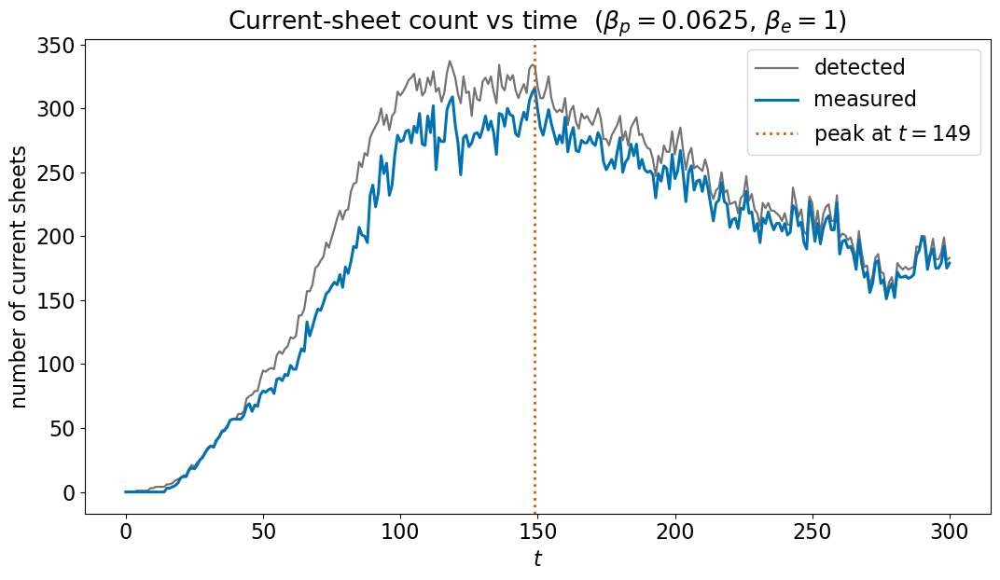

saved cs_count_vs_time_beta0.0625.png

  beta_p   peak N   at t   mean N   rings   tiny  skipped
---------------------------------------------------------
  0.0625      316    149    190.3    5587     11     8.9%

'skipped' is the fraction of detected regions left out of the statistics.
If it varies with beta, the pooled statistics are drawn from a
beta-dependent subsample -- worth checking before fitting exponents.


In [3]:
# =====================================================================
#  Number of current sheets vs time  --  standalone, and deliberately CHEAP
# ---------------------------------------------------------------------
#  Runs your detection on each snapshot and just COUNTS the sheets. No
#  centreline, no Dijkstra, no medial axis -- so this is far quicker than the
#  length/thickness scripts. With the filtered fields already cached it is
#  dominated by reading the HDF5 files.
#
#  For every snapshot it records:
#      n_detected  every region the pipeline labelled
#      n_ring      of those, skipped because the sheet closed round a plasmoid
#      n_tiny      of those, skipped because the centreline is a single pixel
#      n_measured  what is left, i.e. what the statistics are actually built on
#
#  n_ring / n_tiny are the SAME rejection rules used by the length scripts, so
#  n_measured here matches the sheet count there. They cost almost nothing:
#  the ring test is a hole-fill, and the tiny test is a skeletonize with no
#  path-finding afterwards.
#
#  Output:  cs_count_vs_time.png   +   cs_count_vs_time.csv
#
#  Must exist in your session:
#    iterative_filtering3D, partial_x_fft, partial_y_fft, detect_current_sheets
# =====================================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
import h5py
from skimage import morphology, measure
from skimage.morphology import skeletonize
from scipy import ndimage as ndi
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

# -----------------------------
# SETTINGS
# -----------------------------
BETAS      = [0.0625]                        # one line per beta; add more to overlay them
TIMES      = list(range(0, 301))             # EVERY time step
sim_tag    = "ApJ"
base_root  = str(DATA_ROOT)
cache_dir  = str(CACHE / "filtered_cache_Jz")
out_png    = str(RESULTS / f"cs_count_vs_time_beta{BETAS[0]}.png")
out_csv    = str(RESULTS / f"cs_count_vs_time_beta{BETAS[0]}.csv")

STEP          = 1 / 16.0     # one pixel in d_i (only used by the derivatives)
MAX_HOLE_AREA = 20           # a hole bigger than this means the sheet rings a plasmoid
N_WORKERS     = min(len(BETAS) * len(TIMES), os.cpu_count() or 1)
THREADS_PER_WORKER = 1

FILTER_PARAMS = {0.0625: (3, 2.0), 0.25: (3, 2.3), 1: (3, 2.5), 4: (3, 2.7), 16: (3, 3.0)}

plt.rcParams.update({"font.size": 16})
os.makedirs(cache_dir, exist_ok=True)


# ============================================================
# Count the sheets in one (beta, time) snapshot
# ============================================================
def count_snapshot(beta, time):
    base_path = f"{base_root}/beta_p_{beta}/beta_e_1/"
    with h5py.File(base_path + f"Bx_{sim_tag}_t{time}.h5", "r") as fx, \
         h5py.File(base_path + f"By_{sim_tag}_t{time}.h5", "r") as fy, \
         h5py.File(base_path + f"Bz_{sim_tag}_t{time}.h5", "r") as fz:
        Bx, By, Bz = fx["DS1"][:].T, fy["DS1"][:].T, fz["DS1"][:].T

    n_iter, Xi = FILTER_PARAMS[beta]
    cached = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cached):
        d = np.load(cached)
        Bxf, Byf, Bzf = d["Bx"], d["By"], d["Bz"]
    else:
        Bxf, Byf, Bzf = iterative_filtering3D(Bx, By, Bz, n_iter, Xi=Xi)
        np.savez_compressed(cached, Bx=Bxf, By=Byf, Bz=Bzf)

    J_par = np.abs(partial_x_fft(Byf, STEP) - partial_y_fft(Bxf, STEP))

    mask = np.zeros_like(J_par)
    for sheet in detect_current_sheets(J_par):
        for (i, j) in sheet:
            mask[i, j] = 1
    disk = morphology.disk(1)
    mask = morphology.binary_opening(mask, disk)
    mask = morphology.binary_closing(mask, disk)
    mask = morphology.remove_small_objects(mask.astype(bool), min_size=500)
    labelled = measure.label(mask, connectivity=2)

    n_detected = int(labelled.max())
    n_ring = n_tiny = 0
    for k in range(1, n_detected + 1):
        region = labelled == k
        xs, ys = np.where(region)
        crop = region[xs.min():xs.max() + 1, ys.min():ys.max() + 1]
        crop = np.pad(crop, 2, constant_values=False)

        filled = ndi.binary_fill_holes(crop)
        if filled.sum() - crop.sum() > MAX_HOLE_AREA:
            n_ring += 1
            continue
        # a compact blob thins to a single pixel -> no measurable length
        if skeletonize(filled).sum() < 2:
            n_tiny += 1

    return beta, time, n_detected, n_ring, n_tiny, n_detected - n_ring - n_tiny


# ============================================================
# Run every (beta, time)
# ============================================================
tasks = [(b, t) for b in BETAS for t in TIMES]
rows = []
print(f"counting {len(tasks)} snapshots on {N_WORKERS} workers ...", flush=True)
with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=mp.get_context("fork"),
                         initializer=_init_worker,
                         initargs=(THREADS_PER_WORKER,)) as pool:
    jobs = {pool.submit(count_snapshot, b, t): (b, t) for b, t in tasks}
    done = 0
    for job in as_completed(jobs):
        b, t = jobs[job]
        done += 1
        try:
            rows.append(job.result())
            if done % 25 == 0 or done == len(tasks):
                print(f"  [{done}/{len(tasks)}]", flush=True)
        except FileNotFoundError:
            print(f"  beta={b}, t={t}: file missing, skipped", flush=True)
        except Exception as e:
            print(f"  beta={b}, t={t}: {type(e).__name__}: {e}, skipped", flush=True)

if not rows:
    raise SystemExit("nothing counted -- check the paths and TIMES")

data = np.array(sorted(rows, key=lambda r: (r[0], r[1])), float)
COLS = ["beta", "time", "n_detected", "n_ring", "n_tiny", "n_measured"]
with open(out_csv, "w", newline="") as f:
    w = csv.writer(f); w.writerow(COLS); w.writerows(data.tolist())
print(f"\nsaved {out_csv}")


# ============================================================
# The plot: one line per beta
# ============================================================
present = sorted(set(data[:, 0].tolist()))
colours = plt.cm.viridis(np.linspace(0, 0.9, len(present)))

fig, a = plt.subplots(figsize=(11, 6.5))
if len(present) == 1:
    b = present[0]
    m = data[:, 0] == b
    order = np.argsort(data[m, 1])
    t_arr = data[m, 1][order]
    a.plot(t_arr, data[m, 2][order], "-", lw=1.6, color="0.45", label="detected")
    a.plot(t_arr, data[m, 5][order], "-", lw=2.2, color="#0072B2", label="measured")
    peak = int(t_arr[np.argmax(data[m, 5][order])])
    a.axvline(peak, color="#D55E00", ls=":", lw=2, label=rf"peak at $t={peak}$")
    a.set_title(rf"Current-sheet count vs time  ($\beta_p={b:g}$, $\beta_e=1$)")
else:
    for b, c in zip(present, colours):
        m = data[:, 0] == b
        order = np.argsort(data[m, 1])
        a.plot(data[m, 1][order], data[m, 5][order], "-", lw=2, color=c,
               label=rf"$\beta_p={b:g}$")
    a.set_title(r"Current-sheet count vs time  ($\beta_e=1$)")
a.set_xlabel(r"$t$")
a.set_ylabel("number of current sheets")
a.legend()
fig.tight_layout()
fig.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()
print(f"saved {out_png}")


# ============================================================
# Numbers
# ============================================================
print(f"\n{'beta_p':>8}{'peak N':>9}{'at t':>7}{'mean N':>9}"
      f"{'rings':>8}{'tiny':>7}{'skipped':>9}")
print("-" * 57)
for b in present:
    m = data[:, 0] == b
    t_arr, det, ring, tiny, meas = (data[m, 1], data[m, 2], data[m, 3],
                                    data[m, 4], data[m, 5])
    tot = det.sum()
    print(f"{b:>8g}{int(meas.max()):>9d}{int(t_arr[np.argmax(meas)]):>7d}"
          f"{meas.mean():>9.1f}{int(ring.sum()):>8d}{int(tiny.sum()):>7d}"
          f"{100*(ring.sum()+tiny.sum())/max(tot,1):>8.1f}%")
print("\n'skipped' is the fraction of detected regions left out of the statistics.")
print("If it varies with beta, the pooled statistics are drawn from a")
print("beta-dependent subsample -- worth checking before fitting exponents.")